# Copy-Paste Augmentation Demo — Minority Reef Fish Species

This notebook demonstrates the copy-paste augmentation pipeline used to test whether
synthetically boosting the instance count of a single minority species improves
detection/segmentation recall for that species, without touching any other class.

It covers, in order:

1. Why frames with `frame_number < 1000` are excluded from this dataset version.
2. Parsing CVAT's exported instance-segmentation masks (RLE-encoded) directly from
   `annotations.xml`.
3. The donor-eligibility filter: only **whole, unoccluded** fish are used as copy-paste
   sources (`occluded == 0` **and** the mask does not touch the image border).
4. What that filter actually rejects, and why.
5. The data-driven screening that chose this notebook's three candidate species --
   **Raccoon Butterflyfish**, **Forcepsfish**, and **Ornate Butterfly Fish** -- replacing the
   sight-unseen picks (Moorish Idol, Black Triggerfish) made earlier in this notebook's
   history, both later dropped once Section 11 found problems with them.
6. Three blending strategies for compositing a donor fish into a new scene, from a naive
   hard paste up to the two methods used in this project's `copy_paste_augment.py`
   (feathered + colour-matched alpha blending, and Poisson/gradient-domain cloning),
   with a short note on where each comes from in the literature.
7. A side-by-side demo for the three candidate species.
8. Whether feathering (the soft alpha blend at the paste seam) changes the ground-truth
   label, or only the pixels.
9. A per-paste boundary colour-match check, mirroring the reject/retry gate already in
   `copy_paste_augment.py`.
10. A ~30-example gallery per species so you can eyeball many pastes at once, each tagged
    with its boundary colour-match score.
11. Case study: why Moorish Idol was dropped, and the tools that caught it -- kept as a
    methodology record even though it's no longer a candidate species, because the same
    tools (11a-11c) are reused in 11d to double-check the two new picks.
12. The data-driven rationale for the final three-species recommendation.
13. A coverage check: how much of `full_dataset/` this notebook actually found locally.

**A note on images:** `IMAGES_DIR` (below) already points at `../full_dataset`, i.e. this
notebook assumes it lives in `EGH490-2_scripts/copy_paste_species_demo/`, next to your real
frames in `EGH490-2_scripts/full_dataset/`. Run it from that location and every figure uses
your real fish automatically. Wherever a specific frame genuinely isn't found (wrong folder,
or a frame missing from `full_dataset/`), a clearly-labelled *synthetic placeholder* is
generated instead, purely so the notebook degrades gracefully rather than erroring out --
Section 13 reports exactly how much real coverage it found, so you can tell the difference.

In [1]:
import hashlib
import json
import random
import re
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

## Configuration

This notebook lives in `EGH490-2_scripts/copy_paste_species_demo/`, alongside its own
copy of `annotations.xml` / `data.yaml`. Your real frames live one level up, in
`EGH490-2_scripts/full_dataset/`, named `frame_<N>.jpg` -- a different naming convention
from the CVAT export's `nelha-trimmed_mp4-<N>_jpg.rf.<hash>.jpg`, so `IMAGES_DIR` is
indexed by frame number (see `_build_frame_index` below) rather than matched by exact
filename, and resolves either convention to the same file.

Notebook *working directory* isn't always the notebook's own folder -- VS Code in
particular often starts the kernel at the workspace root instead. `_find_dataset_root`
below searches a few likely spots (cwd, `cwd/copy_paste_species_demo`, and a couple of
parent folders) for `annotations.xml` + `data.yaml` so this doesn't depend on getting
that setting right. It prints what it found -- check that line if anything 404s below.

In [2]:
def _find_dataset_root() -> Path:
    cwd = Path.cwd()
    candidates = [cwd, cwd / "copy_paste_species_demo"]
    p = cwd
    for _ in range(4):
        p = p.parent
        candidates += [p, p / "copy_paste_species_demo"]
    for c in candidates:
        if (c / "annotations.xml").exists() and (c / "data.yaml").exists():
            return c
    print(f"Could not find annotations.xml + data.yaml near {cwd} -- checked: "
          + ", ".join(str(c) for c in candidates))
    print("Falling back to the current working directory; set DATASET_ROOT manually below "
          "if that's wrong.")
    return cwd


DATASET_ROOT = _find_dataset_root()
print(f"DATASET_ROOT resolved to: {DATASET_ROOT.resolve()}")
ANNOTATIONS_XML = DATASET_ROOT / "annotations.xml"
DATA_YAML = DATASET_ROOT / "data.yaml"
IMAGES_DIR = DATASET_ROOT.parent / "full_dataset"  # your real frames -- frame_<N>.jpg

MIN_FRAME = 1000  # frames below this were annotated out of numeric order in CVAT and
                   # are not reliably labelled -- see evidence below

# CANDIDATE_SPECIES is decided in Section 5, below, once DATASET and eligible_donors() exist to
# screen candidates against -- it can't be chosen responsibly from this cell alone, which is
# exactly the mistake that led to picking Moorish Idol and Black Triggerfish sight-unseen
# earlier in this notebook's history (both later dropped -- see Section 11 for the forensics,
# and Section 5 for the screening that replaced that approach).

DATASET_ROOT resolved to: /home/claude/aqua_yolo/mirror/EGH490-2_scripts/copy_paste_species_demo


## 1. Why `frame < 1000` is excluded

CVAT walked the frame queue in lexical, not numeric, order (`...,998,999,1000,10,100,
1001,...`), so only a scattered subset of frames below 1000 were ever opened and
annotated by the time of this export. Every frame without an explicit label is treated
as "no fish" by the YOLO format -- which silently mislabels any frame below 1000 that
does contain a fish but simply hadn't been reached yet. The cell below quantifies this
directly from your detection label export rather than asserting it.

In [3]:
def labelled_fraction_by_frame_range(yolo_root: Path, min_frame: int = MIN_FRAME):
    train_txt = yolo_root / "train.txt"
    labels_dir = yolo_root / "labels" / "train"
    frame_re = re.compile(r"mp4-(\d+)_jpg")

    all_frames = []
    with open(train_txt) as f:
        for line in f:
            m = frame_re.search(line)
            if m:
                all_frames.append(int(m.group(1)))

    labelled_frames = set()
    for p in labels_dir.glob("*.txt"):
        m = frame_re.search(p.name)
        if m:
            labelled_frames.add(int(m.group(1)))

    below = [f for f in all_frames if f < min_frame]
    above = [f for f in all_frames if f >= min_frame]
    below_labelled = sum(1 for f in below if f in labelled_frames)
    above_labelled = sum(1 for f in above if f in labelled_frames)

    print(f"frames < {min_frame}:  {len(below):5d} total, {below_labelled:5d} with a label file "
          f"({below_labelled / max(len(below),1):.1%})")
    print(f"frames >= {min_frame}: {len(above):5d} total, {above_labelled:5d} with a label file "
          f"({above_labelled / max(len(above),1):.1%})")
    print()
    print(f"-> below {min_frame}, {1 - below_labelled/max(len(below),1):.0%} of frames have NO label "
          f"file at all, vs. only {1 - above_labelled/max(len(above),1):.0%} above {min_frame}.")
    print("   That gap is annotation coverage, not a real drop in how many frames have fish in them --")
    print("   it's the signature of the out-of-order labelling pass. Dropping frame < "
          f"{min_frame} removes the contaminated region.")


YOLO_EXPORT_ROOT = DATASET_ROOT  # adjust if your train.txt / labels/train live elsewhere
if (YOLO_EXPORT_ROOT / "train.txt").exists():
    labelled_fraction_by_frame_range(YOLO_EXPORT_ROOT)
else:
    print("train.txt not found next to this notebook -- point YOLO_EXPORT_ROOT at your "
          "detection label export to reproduce this check.")

frames < 1000:   1000 total,   131 with a label file (13.1%)
frames >= 1000:  1817 total,  1206 with a label file (66.4%)

-> below 1000, 87% of frames have NO label file at all, vs. only 34% above 1000.
   That gap is annotation coverage, not a real drop in how many frames have fish in them --
   it's the signature of the out-of-order labelling pass. Dropping frame < 1000 removes the contaminated region.


## 2. Parsing CVAT's mask export

CVAT's `<mask>` elements store the segmentation as a run-length encoding (`rle`) over the
tight bounding box (`left, top, width, height`), alternating background/foreground runs
starting from background. The decoder below is verified against a hand-worked example:
the run lengths sum exactly to `width * height`, and the decoded mask's own tight bounding
box fills the given box edge-to-edge, confirming this is a standard full off/on run-length
mask rather than, e.g., a COCO-style compressed RLE.

In [4]:
def decode_cvat_rle(rle_str: str, width: int, height: int) -> np.ndarray:
    """Decode a CVAT <mask rle="..."> string into a (height, width) binary mask."""
    counts = [int(x) for x in rle_str.split(",")]
    total = width * height
    flat = np.zeros(total, dtype=np.uint8)
    pos, val = 0, 0
    for c in counts:
        if val == 1:
            flat[pos:pos + c] = 1
        pos += c
        val = 1 - val
    assert pos == total, f"RLE decoded {pos} pixels, expected {total} -- malformed mask"
    return flat.reshape((height, width))


_IMAGE_BLOCK_RE = re.compile(r"<image\b[^>]*>.*?</image>|<image\b[^>]*/>", re.S)
_IMAGE_ATTR_RE = re.compile(r'id="(\d+)" name="([^"]+)"[^>]*width="(\d+)" height="(\d+)"')
_FRAME_RE = re.compile(r"mp4-(\d+)_jpg")
_MASK_RE = re.compile(
    r'<mask label="([^"]+)" source="[^"]*" occluded="(\d)" rle="([^"]*)" '
    r'left="(\d+)" top="(\d+)" width="(\d+)" height="(\d+)"'
)


def parse_cvat_annotations(xml_path: Path) -> dict:
    """Parse a CVAT 1.1 mask export into {image_name: {frame, iw, ih, instances: [...]}}"""
    content = xml_path.read_text()
    images = {}
    for block in _IMAGE_BLOCK_RE.findall(content):
        attr = _IMAGE_ATTR_RE.search(block)
        if not attr:
            continue
        _, name, iw, ih = attr.group(1), attr.group(2), int(attr.group(3)), int(attr.group(4))
        fm = _FRAME_RE.search(name)
        frame = int(fm.group(1)) if fm else None
        instances = []
        for mm in _MASK_RE.finditer(block):
            label, occluded, rle, left, top, w, h = mm.groups()
            left, top, w, h = int(left), int(top), int(w), int(h)
            edge_touch = (left <= 0) or (top <= 0) or (left + w >= iw) or (top + h >= ih)
            instances.append({
                "label": label, "occluded": int(occluded), "rle": rle,
                "bbox": (left, top, w, h), "edge": edge_touch,
            })
        images[name] = {"frame": frame, "iw": iw, "ih": ih, "instances": instances}
    return images


DATASET = parse_cvat_annotations(ANNOTATIONS_XML)
total_instances = sum(len(d["instances"]) for d in DATASET.values())
print(f"Parsed {len(DATASET)} images, {total_instances} mask instances, "
      f"{sum(1 for d in DATASET.values() if d['frame'] is not None and d['frame'] >= MIN_FRAME)} "
      f"images at frame >= {MIN_FRAME}.")

Parsed 2817 images, 4423 mask instances, 1817 images at frame >= 1000.


## 3. Donor eligibility: whole, unoccluded fish only

A fish is only usable as a copy-paste **donor** if:

- `occluded == 0` in CVAT (the annotator marked the whole body visible), **and**
- its mask does not touch the image border on any side (a fish cut off by the frame edge
  isn't a complete, pasteable shape).

Both checks use information CVAT already gives us per-instance -- no heuristics needed.

In [5]:
def eligible_donors(dataset: dict, species: str, min_frame: int = MIN_FRAME, min_dim: int = 0):
    """Return [(image_name, instance_dict), ...] for whole, unoccluded, frame>=min_frame instances.
    `min_dim` optionally also requires the mask's bbox shorter side to be at least this many
    pixels -- see Section 11a for why that's worth having as a knob, and the real cost/benefit
    numbers per species before turning it on."""
    out = []
    for name, d in dataset.items():
        if d["frame"] is None or d["frame"] < min_frame:
            continue
        for inst in d["instances"]:
            if inst["label"] == species and inst["occluded"] == 0 and not inst["edge"]:
                if min_dim and min(inst["bbox"][2], inst["bbox"][3]) < min_dim:
                    continue
                out.append((name, inst))
    return out


def class_donor_table(dataset: dict, min_frame: int = MIN_FRAME) -> pd.DataFrame:
    rows = defaultdict(lambda: {"total": 0, "post_filter": 0, "unoccluded": 0, "eligible": 0})
    for d in dataset.values():
        for inst in d["instances"]:
            r = rows[inst["label"]]
            r["total"] += 1
            if d["frame"] is not None and d["frame"] >= min_frame:
                r["post_filter"] += 1
                if inst["occluded"] == 0:
                    r["unoccluded"] += 1
                    if not inst["edge"]:
                        r["eligible"] += 1
    df = pd.DataFrame.from_dict(rows, orient="index")
    df.index.name = "species"
    return df.sort_values("post_filter", ascending=False)


donor_table = class_donor_table(DATASET)
donor_table.to_csv("class_donor_eligibility.csv")
donor_table.head(15)

,total,post_filter,unoccluded,eligible
species,,,,
Yellow Tang,1185,1116,1031,957
Brown Surgeonfish,899,874,819,750
Orangeband Surgeonfish,570,566,433,361
Blackfin Chromis,415,310,310,297
Goldring Surgeonfish,254,249,235,205
Moorish Idol,143,143,140,135
Raccoon Butterflyfish,101,101,100,95
Ornate Butterfly Fish,99,99,93,86
Forcepsfish,100,93,86,82


## 4. What the filter actually rejects

A quick visual check that the `occluded` / edge-touching filters are doing something real:
one accepted donor next to one rejected donor for the same species, masks overlaid.

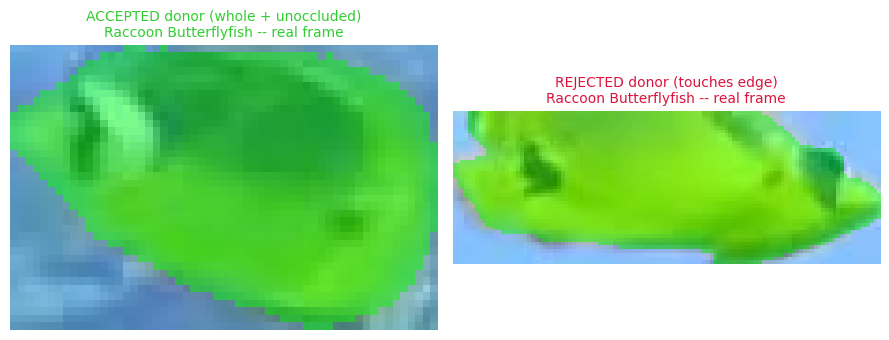

In [6]:
def synthetic_background(width: int, height: int, seed_key: str) -> np.ndarray:
    """Deterministic placeholder reef-ish background, used only when a real frame is missing."""
    rng = np.random.RandomState(int(hashlib.md5(seed_key.encode()).hexdigest(), 16) % (2**32))
    base = np.zeros((height, width, 3), dtype=np.float32)
    top_color = np.array([40, 110, 130], dtype=np.float32)
    bottom_color = np.array([10, 40, 60], dtype=np.float32)
    for y in range(height):
        t = y / max(height - 1, 1)
        base[y, :, :] = top_color * (1 - t) + bottom_color * t
    noise = rng.normal(0, 8, size=(height, width, 3))
    base += noise
    for _ in range(25):
        cx, cy = rng.randint(0, width), rng.randint(0, height)
        r = rng.randint(10, 40)
        yy, xx = np.ogrid[:height, :width]
        mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
        base[mask] += rng.normal(0, 10)
    return np.clip(base, 0, 255).astype(np.uint8)


def synthetic_fish_patch(width: int, height: int, mask: np.ndarray, seed_key: str) -> np.ndarray:
    """Deterministic placeholder fish colouring, confined to `mask`, used only as a stand-in."""
    rng = np.random.RandomState(int(hashlib.md5(seed_key.encode()).hexdigest(), 16) % (2**32))
    palette = [
        np.array([235, 180, 40]),   # yellow-ish
        np.array([230, 140, 30]),   # orange-ish
        np.array([20, 20, 25]),     # near-black
    ]
    body = palette[rng.randint(0, len(palette))]
    patch = np.tile(body, (height, width, 1)).astype(np.float32)
    patch += rng.normal(0, 6, size=(height, width, 3))
    return np.clip(patch, 0, 255).astype(np.uint8)


IS_SYNTHETIC = {}  # image_name -> bool, tracked so figure titles can say so honestly
_FRAME_INDEX_CACHE = None  # frame_number (int) -> Path, built lazily from IMAGES_DIR


def _build_frame_index() -> dict:
    """Your raw frame folder uses `frame_<N>.jpg`, which doesn't match the CVAT export's
    `nelha-trimmed_mp4-<N>_jpg.rf.<hash>.jpg` names -- index by frame number so either
    naming convention resolves to the same file."""
    index = {}
    if IMAGES_DIR.exists():
        for p in IMAGES_DIR.rglob("frame_*.jpg"):
            m = re.match(r"frame_(\d+)\.jpg$", p.name)
            if m:
                index[int(m.group(1))] = p
    return index


def _prefer_locally_available(name_frame_pairs):
    """If any candidate's frame is already on disk, restrict to those (so the demo uses real
    images wherever possible); otherwise fall back to the full candidate list (synthetic)."""
    global _FRAME_INDEX_CACHE
    if _FRAME_INDEX_CACHE is None:
        _FRAME_INDEX_CACHE = _build_frame_index()
    local = [p for p in name_frame_pairs if p[1] in _FRAME_INDEX_CACHE]
    return local if local else name_frame_pairs


def load_image(name: str, iw: int, ih: int, frame: int = None) -> np.ndarray:
    global _FRAME_INDEX_CACHE
    candidates = [IMAGES_DIR / name, IMAGES_DIR / "train" / name, DATASET_ROOT / name]
    if frame is not None:
        if _FRAME_INDEX_CACHE is None:
            _FRAME_INDEX_CACHE = _build_frame_index()
        if frame in _FRAME_INDEX_CACHE:
            candidates.insert(0, _FRAME_INDEX_CACHE[frame])
    for candidate in candidates:
        if candidate.exists():
            IS_SYNTHETIC[name] = False
            img = cv2.imread(str(candidate))
            return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    IS_SYNTHETIC[name] = True
    return synthetic_background(iw, ih, name)


def get_donor_patch(image_name: str, instance: dict):
    d = DATASET[image_name]
    left, top, w, h = instance["bbox"]
    mask = decode_cvat_rle(instance["rle"], w, h)
    img = load_image(image_name, d["iw"], d["ih"], frame=d["frame"])
    if IS_SYNTHETIC.get(image_name):
        patch = synthetic_fish_patch(w, h, mask, image_name + instance["label"])
    else:
        patch = img[top:top + h, left:left + w]
    return patch, mask


def show_accept_reject_demo(species: str):
    accepted = eligible_donors(DATASET, species)
    rejected = []
    for name, d in DATASET.items():
        if d["frame"] is None or d["frame"] < MIN_FRAME:
            continue
        for inst in d["instances"]:
            if inst["label"] == species and (inst["occluded"] == 1 or inst["edge"]):
                rejected.append((name, inst))
    if not accepted or not rejected:
        print(f"Not enough examples to demo for {species} (accepted={len(accepted)}, rejected={len(rejected)})")
        return

    # prefer a locally-available real frame for each panel when one exists
    acc_local = _prefer_locally_available([(n, DATASET[n]["frame"]) for n, _ in accepted])
    acc_frames = {f for _, f in acc_local}
    accepted_pref = [ni for ni in accepted if DATASET[ni[0]]["frame"] in acc_frames] or accepted

    rej_local = _prefer_locally_available([(n, DATASET[n]["frame"]) for n, _ in rejected])
    rej_frames = {f for _, f in rej_local}
    rejected_pref = [ni for ni in rejected if DATASET[ni[0]]["frame"] in rej_frames] or rejected

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    for ax, (name, inst), verdict, color in [
        (axes[0], accepted_pref[0], "ACCEPTED donor", "limegreen"),
        (axes[1], rejected_pref[0], "REJECTED donor", "crimson"),
    ]:
        patch, mask = get_donor_patch(name, inst)
        overlay = patch.copy()
        overlay[mask == 1] = (0.55 * overlay[mask == 1] + 0.45 * np.array([0, 255, 0])).astype(np.uint8)
        ax.imshow(overlay)
        tag = "synthetic placeholder" if IS_SYNTHETIC.get(name) else "real frame"
        reason = "occluded" if inst["occluded"] == 1 and verdict.startswith("REJ") else (
            "touches edge" if verdict.startswith("REJ") else "whole + unoccluded")
        ax.set_title(f"{verdict} ({reason})\n{species} -- {tag}", color=color, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"demo_accept_reject_{species.replace(' ', '_')}.png", dpi=110)
    plt.show()


show_accept_reject_demo("Raccoon Butterflyfish")

## 5. Choosing which species to test

Moorish Idol is dropped from this chapter -- not for a mistake in its annotations, but
because its own colouring (strong black/white/yellow banding) turned out to interact badly
with this copy-paste pipeline specifically (the full forensic investigation is kept as a case
study in Section 11, since the diagnostic tools built there are worth having on record and are
reused below to confirm the replacements). Picking the next candidates sight-unseen would risk
repeating that mistake, so this section screens the *other* 56 classes quantitatively first,
the same way Raccoon Butterflyfish and Moorish Idol should have been screened originally:

1. Not already explained by a confound this project has identified -- excludes Orangeband
   Surgeonfish and every other Acanthuridae member (tangs/surgeonfish), since that family's
   performance story is already a separate, confounded finding (schooling/crowding), and
   excludes Moorish Idol and Black Triggerfish (already tried, already dropped -- Section 11
   and the intro note above).
2. Enough eligible donor crops for real visual variety, not one crop pasted repeatedly.
3. A size distribution that isn't dominated by tiny instances -- Section 11a's lesson is that
   very small donors tend to carry coarse masks and, per Section 11b, sometimes genuinely hazy
   colour, so a species where *most* donors are already small is a species working against
   itself before the blend code even runs.
4. Where this project's existing detection/segmentation results (the class performance doc)
   already flag a species as a documented weak performer, that's a bonus, not a requirement --
   it ties the copy-paste investigation directly to a result already in the thesis.

In [7]:
FAMILY_GUESS = {  # best-effort, common-name-based -- same caveat as the earlier family analysis
    "Raccoon Butterflyfish": "Chaetodontidae", "Ornate Butterfly Fish": "Chaetodontidae",
    "Forcepsfish": "Chaetodontidae", "Fourspot Butterflyfish": "Chaetodontidae",
    "Multiband Butterflyfish": "Chaetodontidae", "Lined Butterflyfish": "Chaetodontidae",
    "Lognnose Butterflyfish": "Chaetodontidae", "Pyramid Butterflyfish": "Chaetodontidae",
    "Threadfin Butterflyfish": "Chaetodontidae",
    "Moorish Idol": "Zanclidae (monotypic)",
    "Black Triggerfish": "Balistidae", "Bridled Triggerfish": "Balistidae",
    "Lei Triggerfish": "Balistidae", "Pinktail Triggerfish": "Balistidae",
    "Yellow Tang": "Acanthuridae", "Brown Surgeonfish": "Acanthuridae",
    "Orangeband Surgeonfish": "Acanthuridae", "Goldring Surgeonfish": "Acanthuridae",
    "Convict Tang": "Acanthuridae", "Chevron Tang": "Acanthuridae",
    "Whitebar Surgeonfish": "Acanthuridae", "Whitecheek Surgeonfish": "Acanthuridae",
    "Whitespotted Surgeonfish": "Acanthuridae", "Bluelined Surgeonfish": "Acanthuridae",
    "Bullethead Unicornfish": "Acanthuridae", "Orangespine Unicornfish": "Acanthuridae",
    "Ringtail Surgeonfish": "Acanthuridae", "Acanthuridae": "Acanthuridae",
    "Blackfin Chromis": "Pomacentridae", "Redlip Parrotfish - Female": "Scaridae",
    "Lowfin Chub": "Kyphosidae (best guess)",
}
ALREADY_DECIDED = {"Raccoon Butterflyfish", "Moorish Idol", "Black Triggerfish"}

screen = donor_table[donor_table["eligible"] >= 20].copy()
screen["family"] = [FAMILY_GUESS.get(s, "unknown") for s in screen.index]
screen = screen[~screen["family"].eq("Acanthuridae") & ~screen.index.isin(ALREADY_DECIDED)]

size_rows = {}
for sp in screen.index:
    donors = eligible_donors(DATASET, sp)
    min_dims = [min(inst["bbox"][2], inst["bbox"][3]) for _, inst in donors]
    size_rows[sp] = {"median_min_dim": np.median(min_dims),
                      "frac_small_lt20px": np.mean(np.array(min_dims) < 20)}
screen = screen.join(pd.DataFrame.from_dict(size_rows, orient="index"))
screen = screen.sort_values("eligible", ascending=False)
print("Candidate species (eligible >= 20, Acanthuridae and already-decided species excluded):\n")
print(screen[["eligible", "family", "median_min_dim", "frac_small_lt20px"]].round(2).to_string())

Candidate species (eligible >= 20, Acanthuridae and already-decided species excluded):

                            eligible                   family  median_min_dim  frac_small_lt20px
species                                                                                         
Blackfin Chromis                 297            Pomacentridae            19.0               0.55
Ornate Butterfly Fish             86           Chaetodontidae            27.5               0.21
Forcepsfish                       82           Chaetodontidae            23.0               0.40
Redlip Parrotfish - Female        25                 Scaridae            30.0               0.08
Lowfin Chub                       23  Kyphosidae (best guess)            53.0               0.00
Lei Triggerfish                   21               Balistidae            43.0               0.05
Fourspot Butterflyfish            20           Chaetodontidae            19.0               0.55


Reading this table: **Forcepsfish** stands out for a reason beyond this table alone -- it's a
species this project's own detection/segmentation results already flagged as a secondary weak
performer (class performance analysis, 2026-09: residual -0.109 against the instance-count
trend), with a healthy 82 eligible donor crops here to work with. **Ornate Butterfly Fish**
is the cleanest of the rest by this table -- a solid donor count, a size distribution that
isn't small-instance-heavy (median ~28px, only ~21% under 20px, close to Raccoon
Butterflyfish's own profile), and -- confirmed properly in Section 11d, once the colour-risk
diagnostic exists -- no sign of Moorish Idol's size-correlated colour problem.

Both are Chaetodontidae, the same family as Raccoon Butterflyfish -- which trades away the
"different families" diversity bonus from criterion 4 above. That's a real trade, not an
oversight: the honest alternative with a different family (Blackfin Chromis, Pomacentridae)
has 297 eligible donors but a median size of only ~19-20px with over half its donors under
20px -- i.e. a species that's small in *most* of its instances, not just the unlucky distant
ones, which per the table above is exactly the profile that caused trouble before. Three
butterflyfish species is a smaller taxonomic spread, but it buys a within-family replication
check instead (does copy-paste help consistently across several Chaetodontidae, not just one),
which is a reasonable trade for a cleaner result over a diversity point that would come with
real data-quality risk attached.

In [8]:
CANDIDATE_SPECIES = ["Raccoon Butterflyfish", "Forcepsfish", "Ornate Butterfly Fish"]
print(f"CANDIDATE_SPECIES set to: {CANDIDATE_SPECIES}")

CANDIDATE_SPECIES set to: ['Raccoon Butterflyfish', 'Forcepsfish', 'Ornate Butterfly Fish']


## 6. Blending methods

Three ways to composite the donor patch into a target frame, from worst to closest to
what `copy_paste_augment.py` already does in this project:

- **Naive paste** -- drop the masked pixels straight in. No colour or lighting matching,
  hard mask edges. Included only to show why the other two are worth the extra code.
- **Feathered + colour-matched alpha blend** (`"matched"` mode) -- the donor patch's LAB
  colour statistics are shifted to match the local target background (a Reinhard-style
  transfer), and the binary mask is blurred into a soft alpha so the seam isn't a hard
  edge. This is the standard large-scale-jittering-plus-blending recipe from Ghiasi et al.,
  *"Simple Copy-Paste Is a Strong Data Augmentation Method for Instance Segmentation,"*
  CVPR 2021.
- **Poisson / gradient-domain cloning** (`"poisson"` mode, `cv2.seamlessClone`) -- blends
  in the gradient domain so lighting is matched automatically; this is the method from
  Pérez, Gangnet & Blake, *"Poisson Image Editing,"* SIGGRAPH 2003.

In [9]:
def color_transfer_lab(patch: np.ndarray, mask: np.ndarray, target_region: np.ndarray) -> np.ndarray:
    """Partially shift the patch's LAB statistics (inside mask) toward the local target
    background -- enough to correct lighting/colour-cast, without erasing the donor's own
    identifying colouration. A *full* Reinhard-style transfer (matching mean and std exactly)
    was tried first and over-corrected badly: with a strong colour difference between a
    brightly-marked fish and blue water, it washed the fish out to a near-uniform grey-brown,
    destroying the very features (stripes, colour pattern) a classifier needs. Luminance (L)
    is corrected more than chroma (a, b) for the same reason -- lighting varies a lot more
    than a fish's actual colouration should."""
    patch_lab = cv2.cvtColor(patch, cv2.COLOR_RGB2LAB).astype(np.float32)
    target_lab = cv2.cvtColor(target_region, cv2.COLOR_RGB2LAB).astype(np.float32)

    m = mask.astype(bool)
    if m.sum() < 5:
        return patch

    out = patch_lab.copy()
    channel_strength = (0.45, 0.15, 0.15)  # L, a, b -- correct lighting more than colour
    for c in range(3):
        src_vals = patch_lab[:, :, c][m]
        tgt_vals = target_lab[:, :, c]
        src_mean, src_std = src_vals.mean(), src_vals.std() + 1e-6
        tgt_mean, tgt_std = tgt_vals.mean(), tgt_vals.std() + 1e-6
        s = channel_strength[c]
        # Two guards against a donor with much more internal contrast than its target patch has
        # texture (common for a bold, high-contrast species like Moorish Idol against almost any
        # reef background, not just open water -- see Section 11b for the numbers that justify
        # these specific bounds):
        # 1. tgt_std << src_std would otherwise drag std_ratio toward (1-s), compressing the
        #    donor's OWN contrast toward the target's -- clamped tightly so a low-texture target
        #    can nudge but not flatten the donor's pattern/shading.
        std_ratio = 1 + s * (np.clip(tgt_std / src_std, 0.8, 1.25) - 1)
        # 2. the mean (brightness/cast) shift is capped relative to the donor's own spread, so a
        #    very bright or very dark target can still pull the donor's ambient tone toward it,
        #    but can't single-handedly lift a near-black donor out of "dark" territory.
        shift = np.clip(s * (tgt_mean - src_mean), -0.5 * src_std, 0.5 * src_std)
        out[:, :, c][m] = (src_vals - src_mean) * std_ratio + src_mean + shift
    out = np.clip(out, 0, 255).astype(np.uint8)
    return cv2.cvtColor(out, cv2.COLOR_LAB2RGB)


def feather_mask(mask: np.ndarray, feather_px: int = 5) -> np.ndarray:
    """Binary mask -> soft float alpha in [0, 1] with a blurred border."""
    m = (mask * 255).astype(np.uint8)
    blurred = cv2.GaussianBlur(m, (0, 0), sigmaX=feather_px)
    return (blurred.astype(np.float32) / 255.0)


def paste_naive(target: np.ndarray, patch: np.ndarray, mask: np.ndarray, x: int, y: int) -> np.ndarray:
    out = target.copy()
    h, w = mask.shape
    region = out[y:y + h, x:x + w]
    m = mask.astype(bool)
    region[m] = patch[m]
    out[y:y + h, x:x + w] = region
    return out


def paste_matched_feathered(target: np.ndarray, patch: np.ndarray, mask: np.ndarray,
                             x: int, y: int, feather_px: int = None) -> np.ndarray:
    h, w = mask.shape
    if feather_px is None:
        # A fixed feather radius bleeds badly on small instances: a 5px-sigma Gaussian blur
        # has an effective reach of ~15-20px, which can cover almost the entire box for a
        # 30x40px fish -- producing a faint rectangular "halo" the size of the whole bbox
        # instead of a tight edge around the fish. Scale it down for small masks instead.
        feather_px = max(1, min(5, round(0.06 * min(h, w))))
    local_bg = target[y:y + h, x:x + w]
    matched = color_transfer_lab(patch, mask, local_bg)
    alpha = feather_mask(mask, feather_px)[..., None]
    out = target.copy()
    region = out[y:y + h, x:x + w].astype(np.float32)
    blended = region * (1 - alpha) + matched.astype(np.float32) * alpha
    out[y:y + h, x:x + w] = np.clip(blended, 0, 255).astype(np.uint8)
    return out


def paste_poisson(target: np.ndarray, patch: np.ndarray, mask: np.ndarray, x: int, y: int) -> np.ndarray:
    h, w = mask.shape
    center = (x + w // 2, y + h // 2)
    mask255 = (mask * 255).astype(np.uint8)
    if mask255.sum() == 0:
        return target.copy()
    try:
        out = cv2.seamlessClone(patch, target, mask255, center, cv2.NORMAL_CLONE)
    except cv2.error:
        # seamlessClone can fail on tiny/degenerate masks -- fall back to the feathered blend
        out = paste_matched_feathered(target, patch, mask, x, y)
    return out


def find_placement(target_shape, mask_shape, existing_bboxes, margin: int = 2, tries: int = 30):
    th, tw = target_shape[:2]
    mh, mw = mask_shape
    for _ in range(tries):
        x = random.randint(margin, max(tw - mw - margin, margin))
        y = random.randint(margin, max(th - mh - margin, margin))
        new_box = (x, y, x + mw, y + mh)
        ok = True
        for (bx, by, bw, bh) in existing_bboxes:
            ex_box = (bx, by, bx + bw, by + bh)
            if not (new_box[2] < ex_box[0] or new_box[0] > ex_box[2] or
                    new_box[3] < ex_box[1] or new_box[1] > ex_box[3]):
                ok = False
                break
        if ok:
            return x, y
    return x, y  # last attempt, even if it overlaps slightly

## 7. Side-by-side demo: the three candidate species

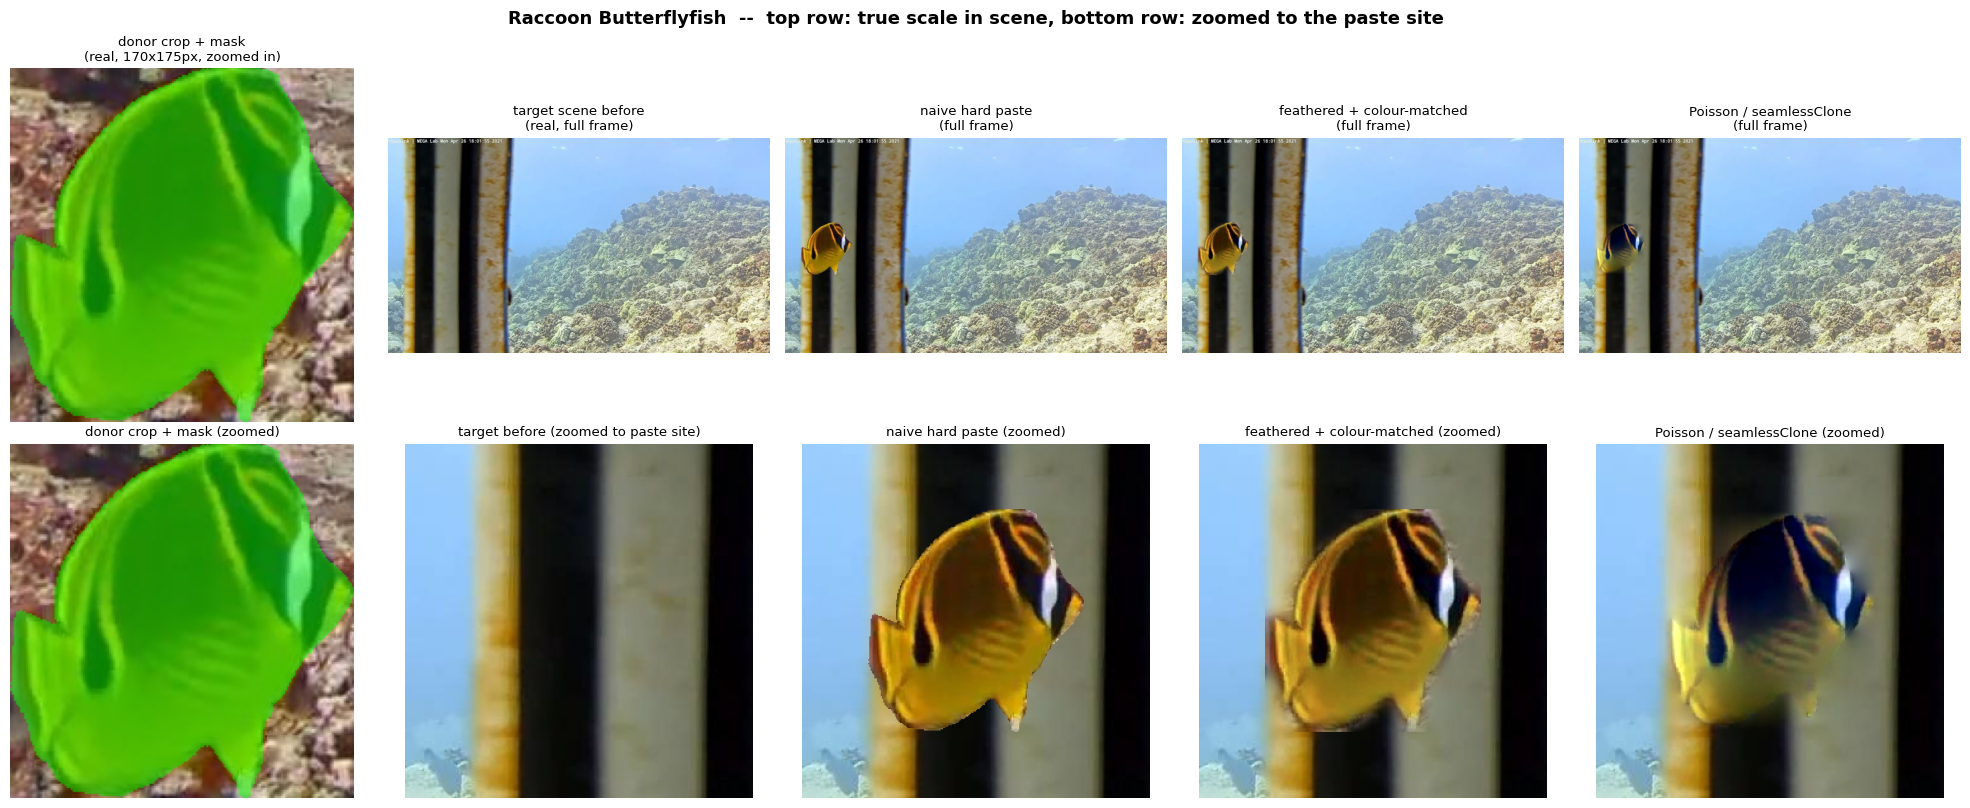

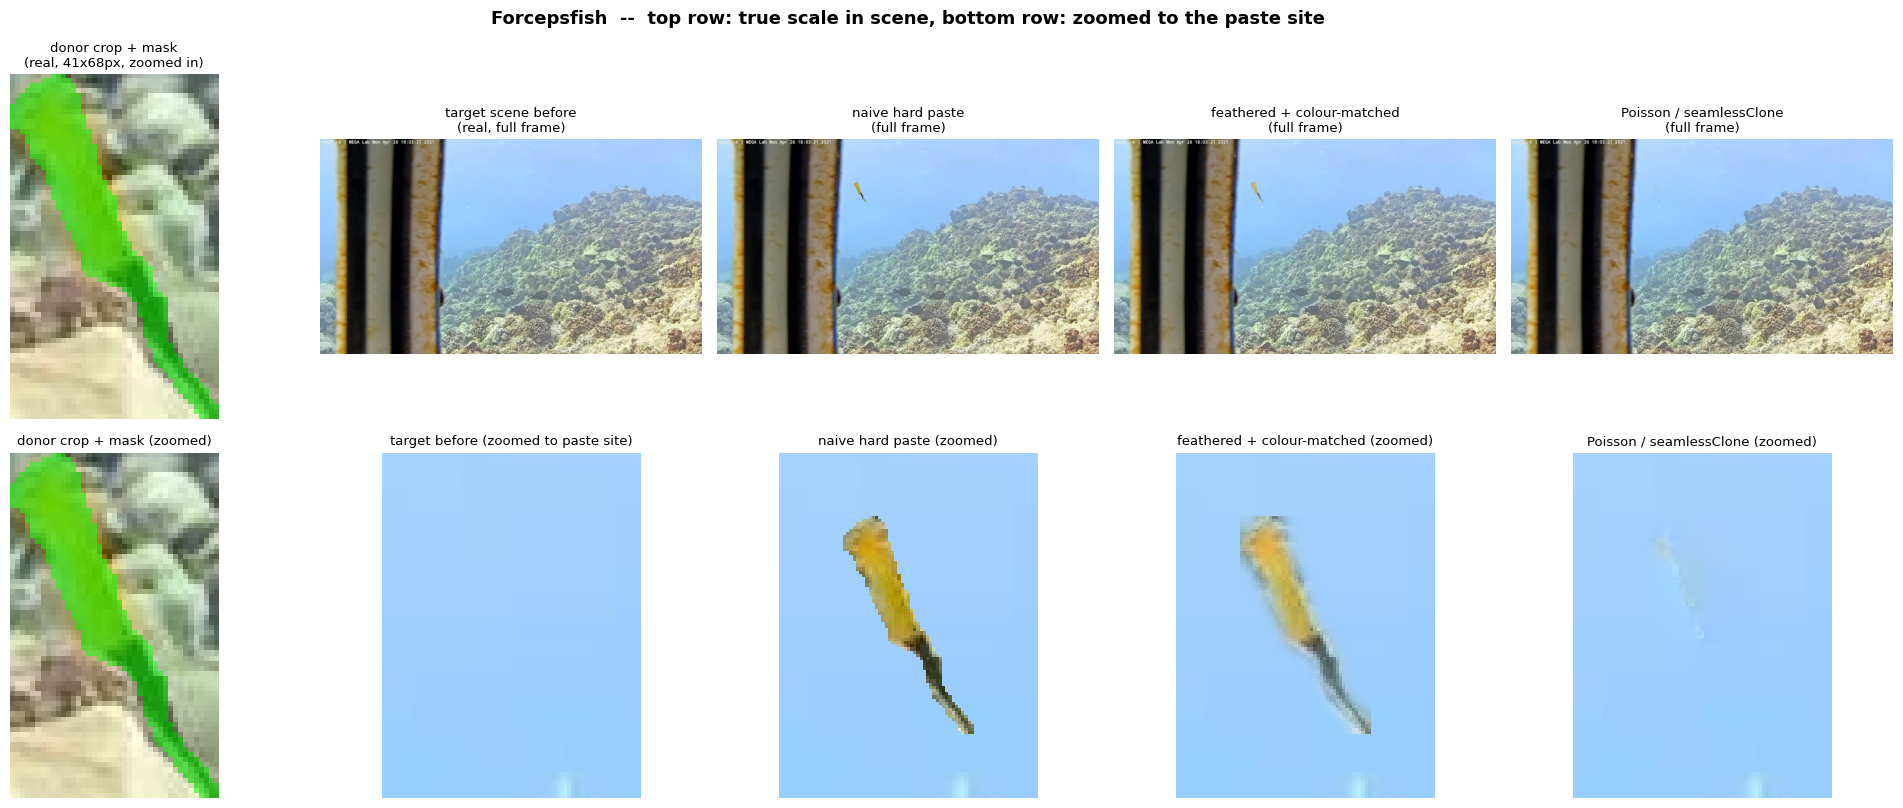

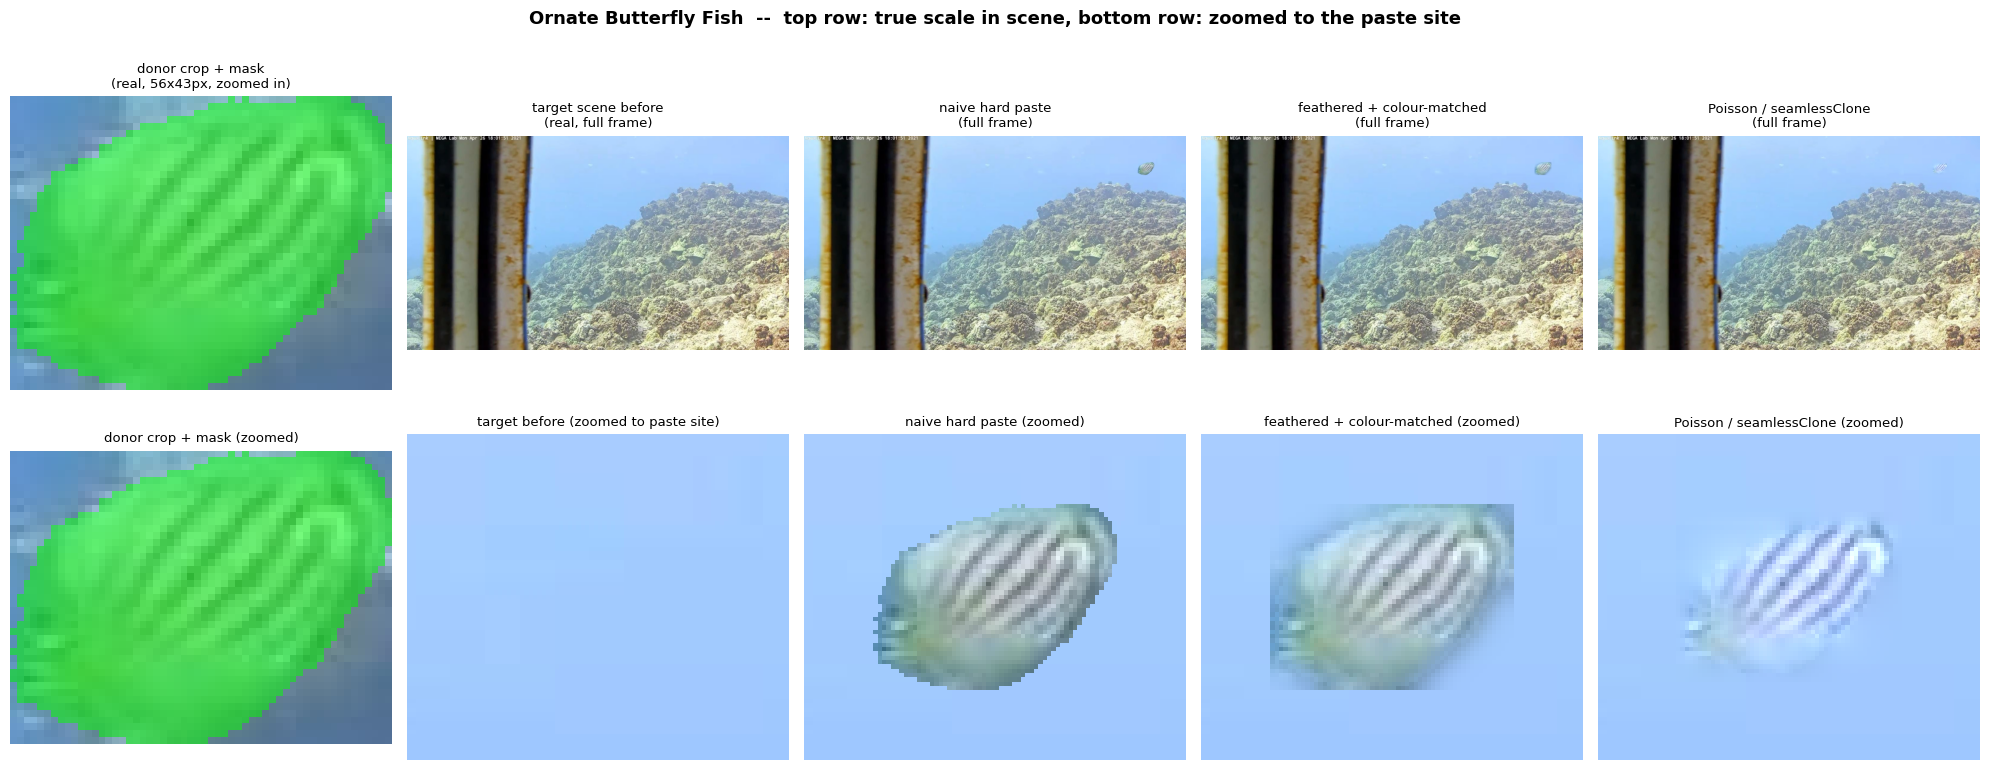

In [10]:
def demo_species(species: str):
    donors = eligible_donors(DATASET, species)
    if not donors:
        print(f"No eligible donors found for {species}")
        return
    # pick the largest eligible donor (by mask bbox area) so the demo is easy to see --
    # the actual augmentation pipeline draws from all eligible donors, not just this one.
    # Prefer a donor whose frame is already staged locally, so this demo shows real fish
    # whenever possible rather than falling back to the synthetic placeholder.
    donor_pool = _prefer_locally_available([(name, DATASET[name]["frame"]) for name, _ in donors])
    donor_frames_allowed = {f for _, f in donor_pool}
    donors_filtered = [nd for nd in donors if DATASET[nd[0]]["frame"] in donor_frames_allowed]
    donor_name, donor_inst = max(donors_filtered, key=lambda nd: nd[1]["bbox"][2] * nd[1]["bbox"][3])
    donor_patch, donor_mask = get_donor_patch(donor_name, donor_inst)

    # pick a target frame: prefer a real sparse frame (<=1 existing instance), frame>=MIN_FRAME,
    # and prefer one already staged locally for the same reason as above
    target_candidates = [
        (name, d) for name, d in DATASET.items()
        if d["frame"] is not None and d["frame"] >= MIN_FRAME and len(d["instances"]) <= 1
    ]
    local_targets = _prefer_locally_available([(name, d["frame"]) for name, d in target_candidates])
    allowed_target_frames = {f for _, f in local_targets}
    target_candidates = [(name, d) for name, d in target_candidates if d["frame"] in allowed_target_frames]
    if target_candidates:
        target_name, target_d = random.choice(target_candidates)
    else:
        target_name = donors[-1][0]
        target_d = DATASET[target_name]
    target_img = load_image(target_name, target_d["iw"], target_d["ih"], frame=target_d["frame"])
    existing_boxes = [inst["bbox"] for inst in target_d["instances"]]

    x, y = find_placement(target_img.shape, donor_mask.shape, existing_boxes)
    mh, mw = donor_mask.shape

    naive = paste_naive(target_img, donor_patch, donor_mask, x, y)
    matched = paste_matched_feathered(target_img, donor_patch, donor_mask, x, y)
    poisson = paste_poisson(target_img, donor_patch, donor_mask, x, y)

    donor_overlay = donor_patch.copy()
    donor_overlay[donor_mask == 1] = (0.5 * donor_overlay[donor_mask == 1]
                                       + 0.5 * np.array([0, 255, 0])).astype(np.uint8)

    # full-frame row: shows true scale of the pasted fish within the scene
    # zoomed row: crops tightly around the paste site so the blend differences are legible
    pad = max(10, int(0.3 * max(mw, mh)))
    cx0, cy0 = max(x - pad, 0), max(y - pad, 0)
    cx1, cy1 = min(x + mw + pad, target_img.shape[1]), min(y + mh + pad, target_img.shape[0])

    fig, axes = plt.subplots(2, 5, figsize=(20, 8.2))
    full_panels = [
        (donor_overlay, f"donor crop + mask\n({'synthetic' if IS_SYNTHETIC.get(donor_name) else 'real'}, "
                         f"{mw}x{mh}px, zoomed in)"),
        (target_img, f"target scene before\n({'synthetic' if IS_SYNTHETIC.get(target_name) else 'real'}, full frame)"),
        (naive, "naive hard paste\n(full frame)"),
        (matched, "feathered + colour-matched\n(full frame)"),
        (poisson, "Poisson / seamlessClone\n(full frame)"),
    ]
    zoom_panels = [
        (donor_overlay, "donor crop + mask (zoomed)"),
        (target_img[cy0:cy1, cx0:cx1], "target before (zoomed to paste site)"),
        (naive[cy0:cy1, cx0:cx1], "naive hard paste (zoomed)"),
        (matched[cy0:cy1, cx0:cx1], "feathered + colour-matched (zoomed)"),
        (poisson[cy0:cy1, cx0:cx1], "Poisson / seamlessClone (zoomed)"),
    ]
    for ax, (img, title) in zip(axes[0], full_panels):
        ax.imshow(img)
        ax.set_title(title, fontsize=9.5)
        ax.axis("off")
    for ax, (img, title) in zip(axes[1], zoom_panels):
        ax.imshow(img)
        ax.set_title(title, fontsize=9.5)
        ax.axis("off")
    fig.suptitle(f"{species}  --  top row: true scale in scene, bottom row: zoomed to the paste site",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"demo_blend_{species.replace(' ', '_')}.png", dpi=110)
    plt.show()


for sp in CANDIDATE_SPECIES:
    demo_species(sp)

**If any panel above says "synthetic placeholder"** instead of "real", `IMAGES_DIR` isn't
finding that particular frame in `full_dataset/` (Section 13's coverage check says exactly
how much it found) -- the figure still renders, just with a procedurally-generated stand-in
fish/background rather than your actual footage, so a placeholder result shouldn't be read
as a judgement on blend quality.

## 8. Does feathering change the label, or only the pixels?

Short answer: **only the pixels.** Feathering (the Gaussian-blurred alpha mask used in
`paste_matched_feathered`) exists purely so the *pixel colours* fade smoothly into the
background instead of stopping at a hard edge -- it's standard alpha-compositing practice,
the same idea as feathering a selection in any image editor, and it's what removes the
visible cookie-cutter outline you can see in the "naive hard paste" column above.

It never touches the *label*. The ground-truth mask written for a synthetic instance is the
donor's original **hard, binary** CVAT mask (the same one decoded in Section 2), placed at
the paste location unchanged -- not the blurred alpha used for blending, and not re-derived
from the composited pixels in any way. Those are two separate things that happen to share a
shape: a soft alpha *for rendering*, and a crisp binary mask *for supervision*. The cell
below makes this concrete by drawing the exact label-mask boundary (the contour of the hard
mask) directly on top of the feathered, blended image -- the boundary line and the visible
soft edge don't coincide, which is the point: the label stays accurate to the fish's true
extent regardless of how gently the pixels were blended.

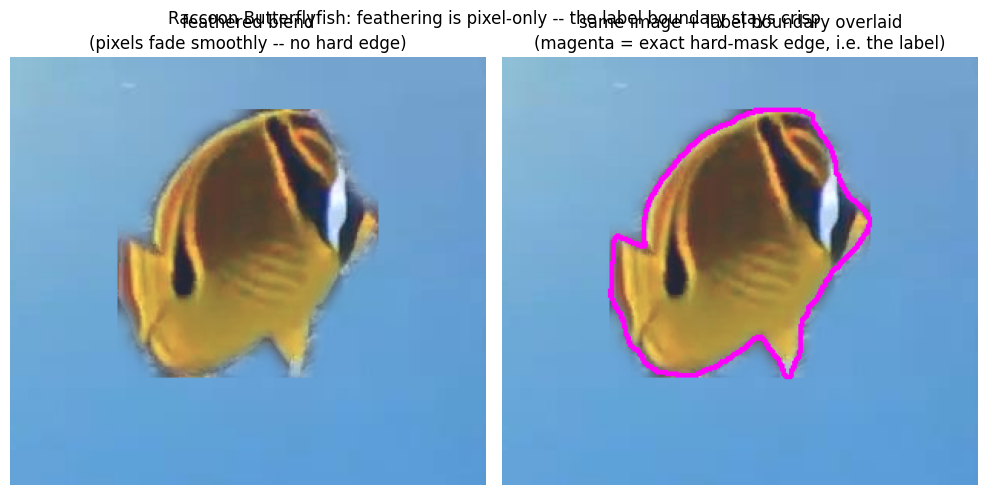

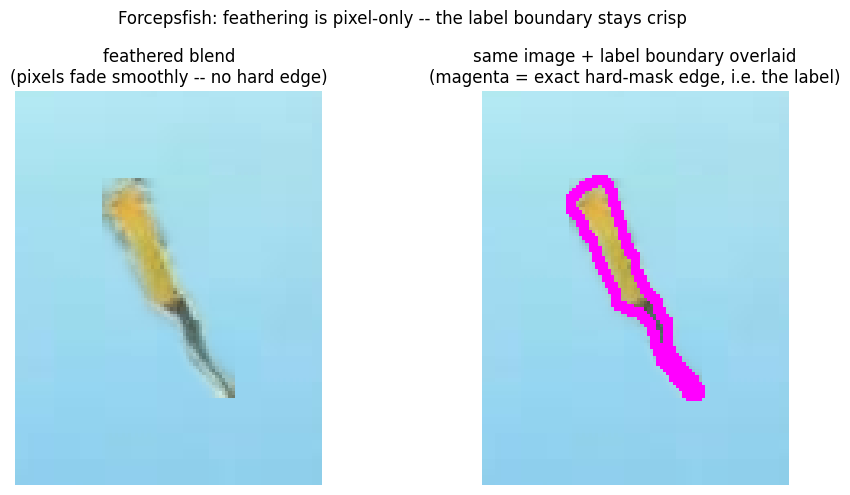

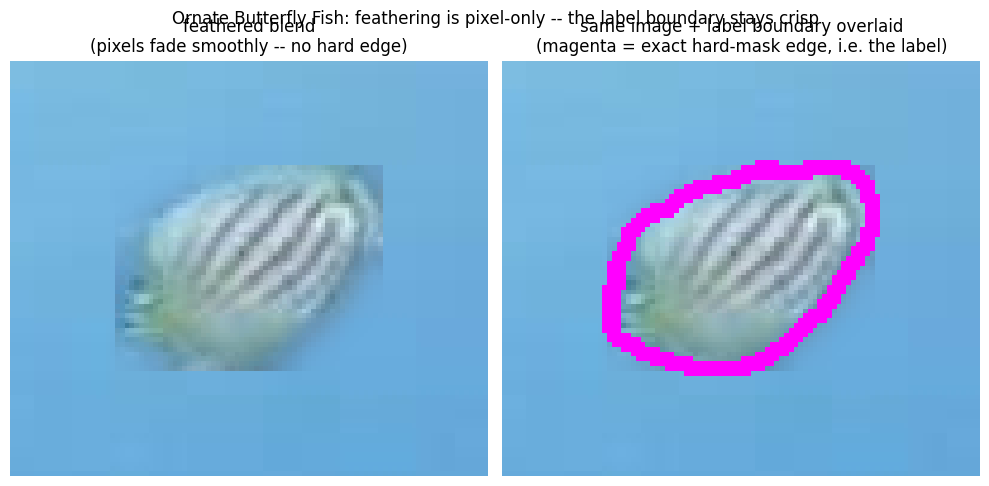

In [11]:
def mask_contour_overlay(image: np.ndarray, mask: np.ndarray, x: int, y: int,
                          color=(255, 0, 255), thickness: int = 2) -> np.ndarray:
    """Draw the hard mask's boundary (i.e. what the YOLO/CVAT label would actually record)
    on top of `image`, at offset (x, y). Purely a visualisation -- does not affect any mask
    used elsewhere."""
    out = image.copy()
    contours, _ = cv2.findContours((mask * 255).astype(np.uint8), cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    shifted = [c + np.array([[x, y]]) for c in contours]
    cv2.drawContours(out, shifted, -1, color, thickness)
    return out


def demo_label_vs_feathering(species: str):
    donors = eligible_donors(DATASET, species)
    if not donors:
        return
    donor_pool = _prefer_locally_available([(n, DATASET[n]["frame"]) for n, _ in donors])
    allowed = {f for _, f in donor_pool}
    donors_f = [nd for nd in donors if DATASET[nd[0]]["frame"] in allowed]
    donor_name, donor_inst = max(donors_f, key=lambda nd: nd[1]["bbox"][2] * nd[1]["bbox"][3])
    donor_patch, donor_mask = get_donor_patch(donor_name, donor_inst)

    target_candidates = [(n, d) for n, d in DATASET.items()
                          if d["frame"] is not None and d["frame"] >= MIN_FRAME and len(d["instances"]) <= 1]
    local_targets = _prefer_locally_available([(n, d["frame"]) for n, d in target_candidates])
    allowed_target_frames = {f for _, f in local_targets}
    target_candidates = [(n, d) for n, d in target_candidates if d["frame"] in allowed_target_frames]
    target_name, target_d = target_candidates[0]
    target_img = load_image(target_name, target_d["iw"], target_d["ih"], frame=target_d["frame"])
    x, y = find_placement(target_img.shape, donor_mask.shape, [i["bbox"] for i in target_d["instances"]])

    blended = paste_matched_feathered(target_img, donor_patch, donor_mask, x, y)
    with_label = mask_contour_overlay(blended, donor_mask, x, y)

    mh, mw = donor_mask.shape
    pad = max(15, int(0.4 * max(mw, mh)))
    cy0, cy1 = max(y - pad, 0), min(y + mh + pad, target_img.shape[0])
    cx0, cx1 = max(x - pad, 0), min(x + mw + pad, target_img.shape[1])

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(blended[cy0:cy1, cx0:cx1])
    axes[0].set_title("feathered blend\n(pixels fade smoothly -- no hard edge)")
    axes[1].imshow(with_label[cy0:cy1, cx0:cx1])
    axes[1].set_title("same image + label boundary overlaid\n(magenta = exact hard-mask edge, i.e. the label)")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{species}: feathering is pixel-only -- the label boundary stays crisp", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"demo_label_vs_feather_{species.replace(' ', '_')}.png", dpi=110)
    plt.show()


for sp in CANDIDATE_SPECIES:
    demo_label_vs_feathering(sp)

## 9. Boundary colour-match check

A visual blend can still look wrong in a way that's easy to miss by eye, especially across
many examples -- so this gives it a number. `boundary_mismatch_score` samples a thin ring of
pixels just *inside* the pasted mask and a thin ring just *outside* it (after blending), and
reports their colour distance in LAB space (roughly, perceptual colour difference -- 0 is a
perfect match, upward of ~15-20 is a seam a person would likely notice). This is the same
idea as the boundary-colour-mismatch reject/retry gate already in `copy_paste_augment.py`:
that gate uses a version of this score to automatically reject a placement and try another
donor/location when the seam is too visible, rather than silently keeping a bad paste. Here
it's surfaced as a number on each thumbnail instead of a hidden accept/reject decision, so
you can see the actual range of scores your dataset produces, not just the end result.

In [12]:
def _ring_masks(mask: np.ndarray, ring_px: int = 3):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * ring_px + 1, 2 * ring_px + 1))
    m8 = (mask * 255).astype(np.uint8)
    eroded = cv2.erode(m8, k) > 0
    dilated = cv2.dilate(m8, k) > 0
    inner_ring = mask.astype(bool) & ~eroded
    outer_ring = dilated & ~mask.astype(bool)
    return inner_ring, outer_ring


def boundary_mismatch_score(composited_region_rgb: np.ndarray, mask: np.ndarray,
                             ring_px: int = 3) -> float:
    """LAB colour distance between a ring of pixels just inside vs. just outside the pasted
    mask, in the final (already-blended) image. Lower = better-matched seam."""
    inner_ring, outer_ring = _ring_masks(mask, ring_px)
    if inner_ring.sum() < 5 or outer_ring.sum() < 5:
        return float("nan")
    lab = cv2.cvtColor(composited_region_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    inner_mean = lab[inner_ring].mean(axis=0)
    outer_mean = lab[outer_ring].mean(axis=0)
    return float(np.linalg.norm(inner_mean - outer_mean))

## 10. ~30-example gallery per species

Many different (donor, target, placement) combinations for each candidate species, using
the `matched` blend (the one actually intended for the real augmentation run -- `poisson`'s
colour-bleeding tradeoff from Section 7 makes it a harder default to trust unsupervised
across many placements). Each tile's title is its boundary mismatch score from Section 9, so
you can scan for outliers at a glance instead of eyeballing all 30 individually. This draws
from every eligible donor and every sparse target frame currently found under `IMAGES_DIR`
(Section 13's coverage check says how many that is); with the full `full_dataset/` folder
behind it, that's up to the full eligible-donor count per species.

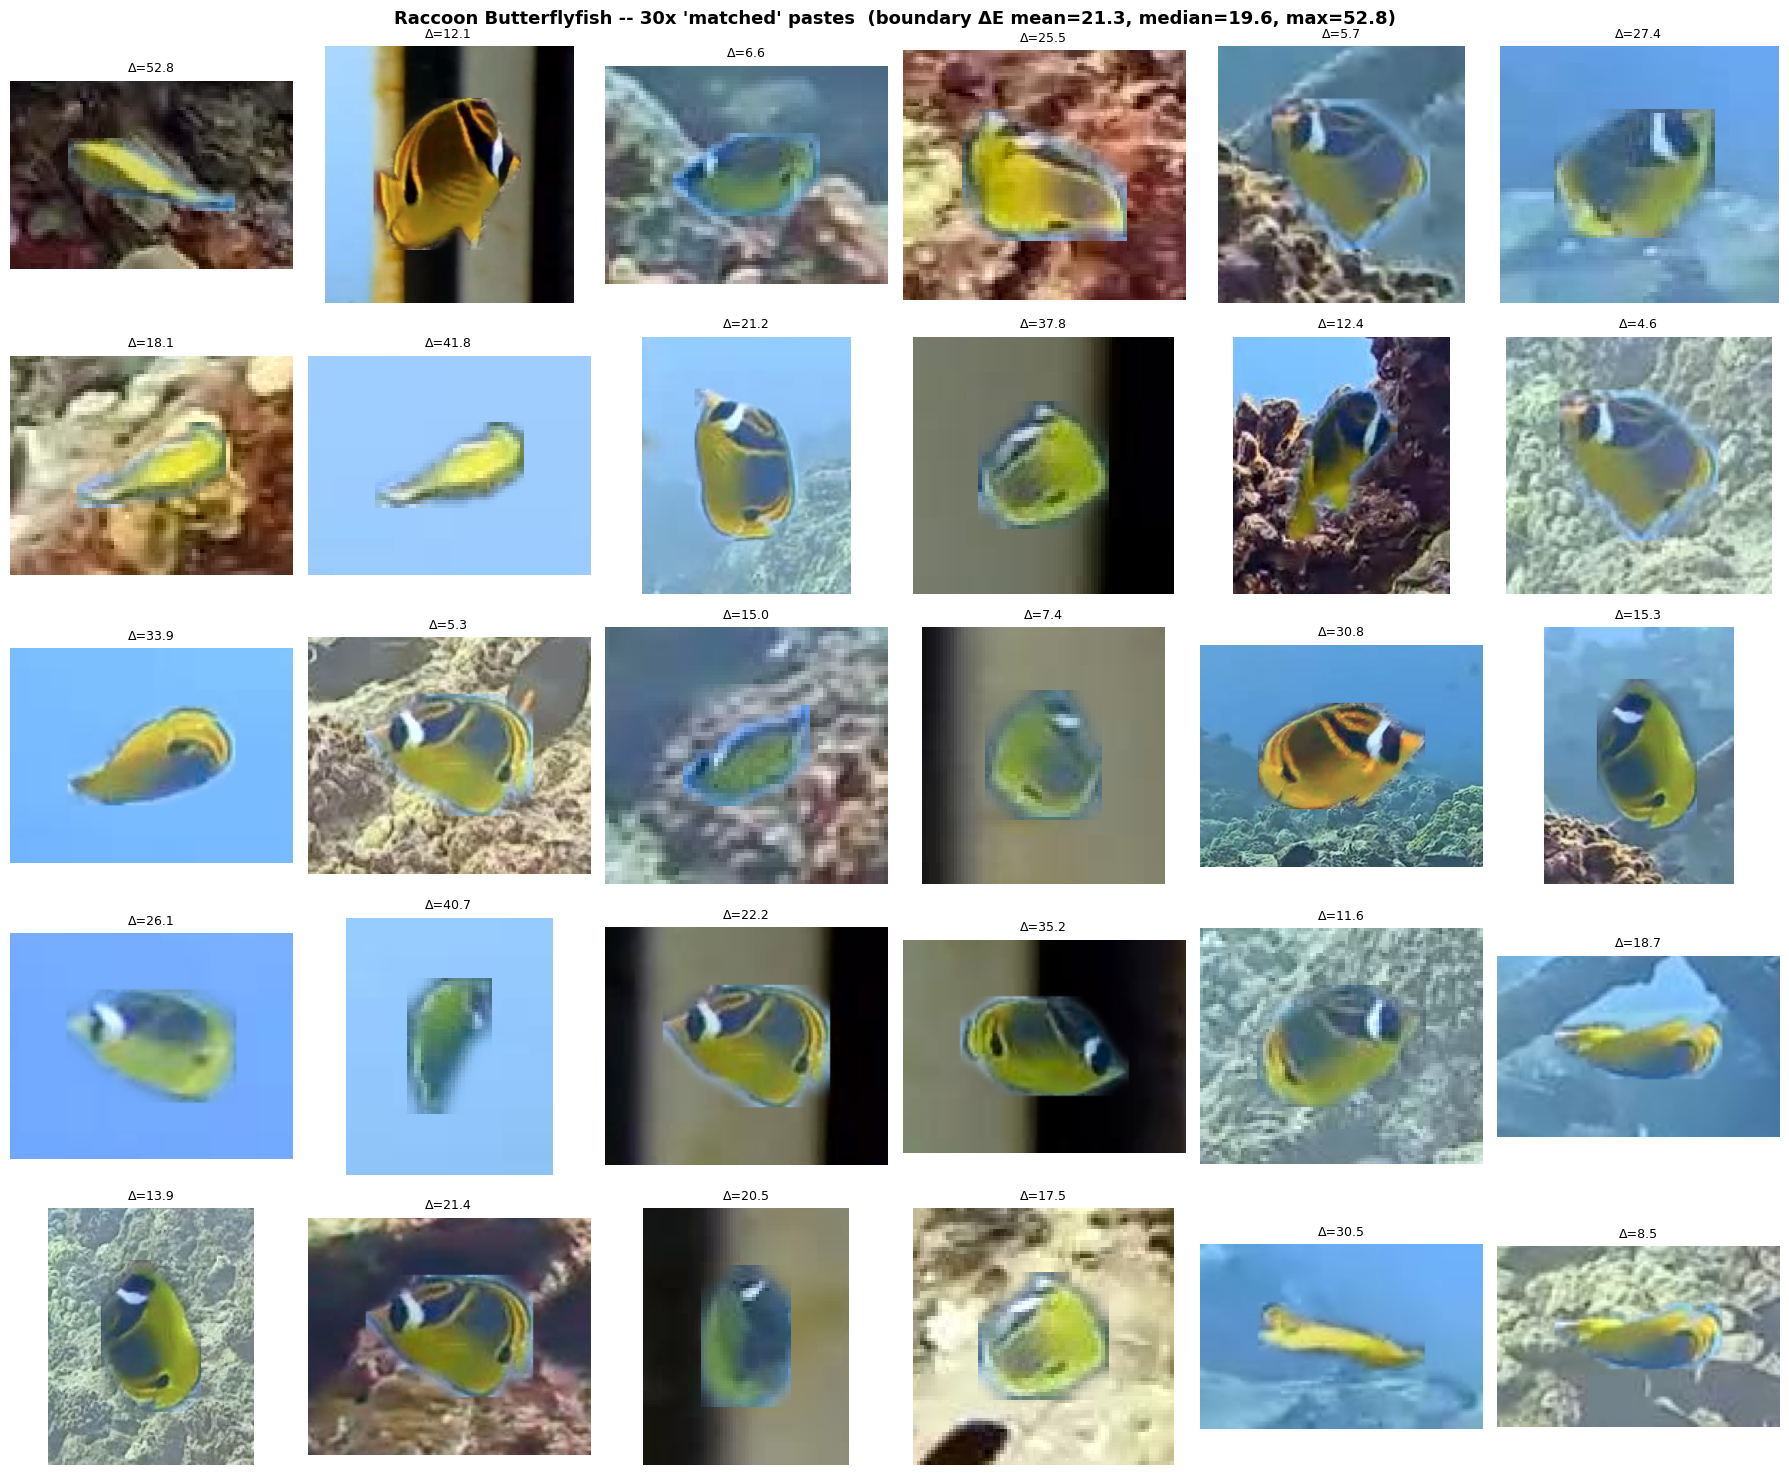

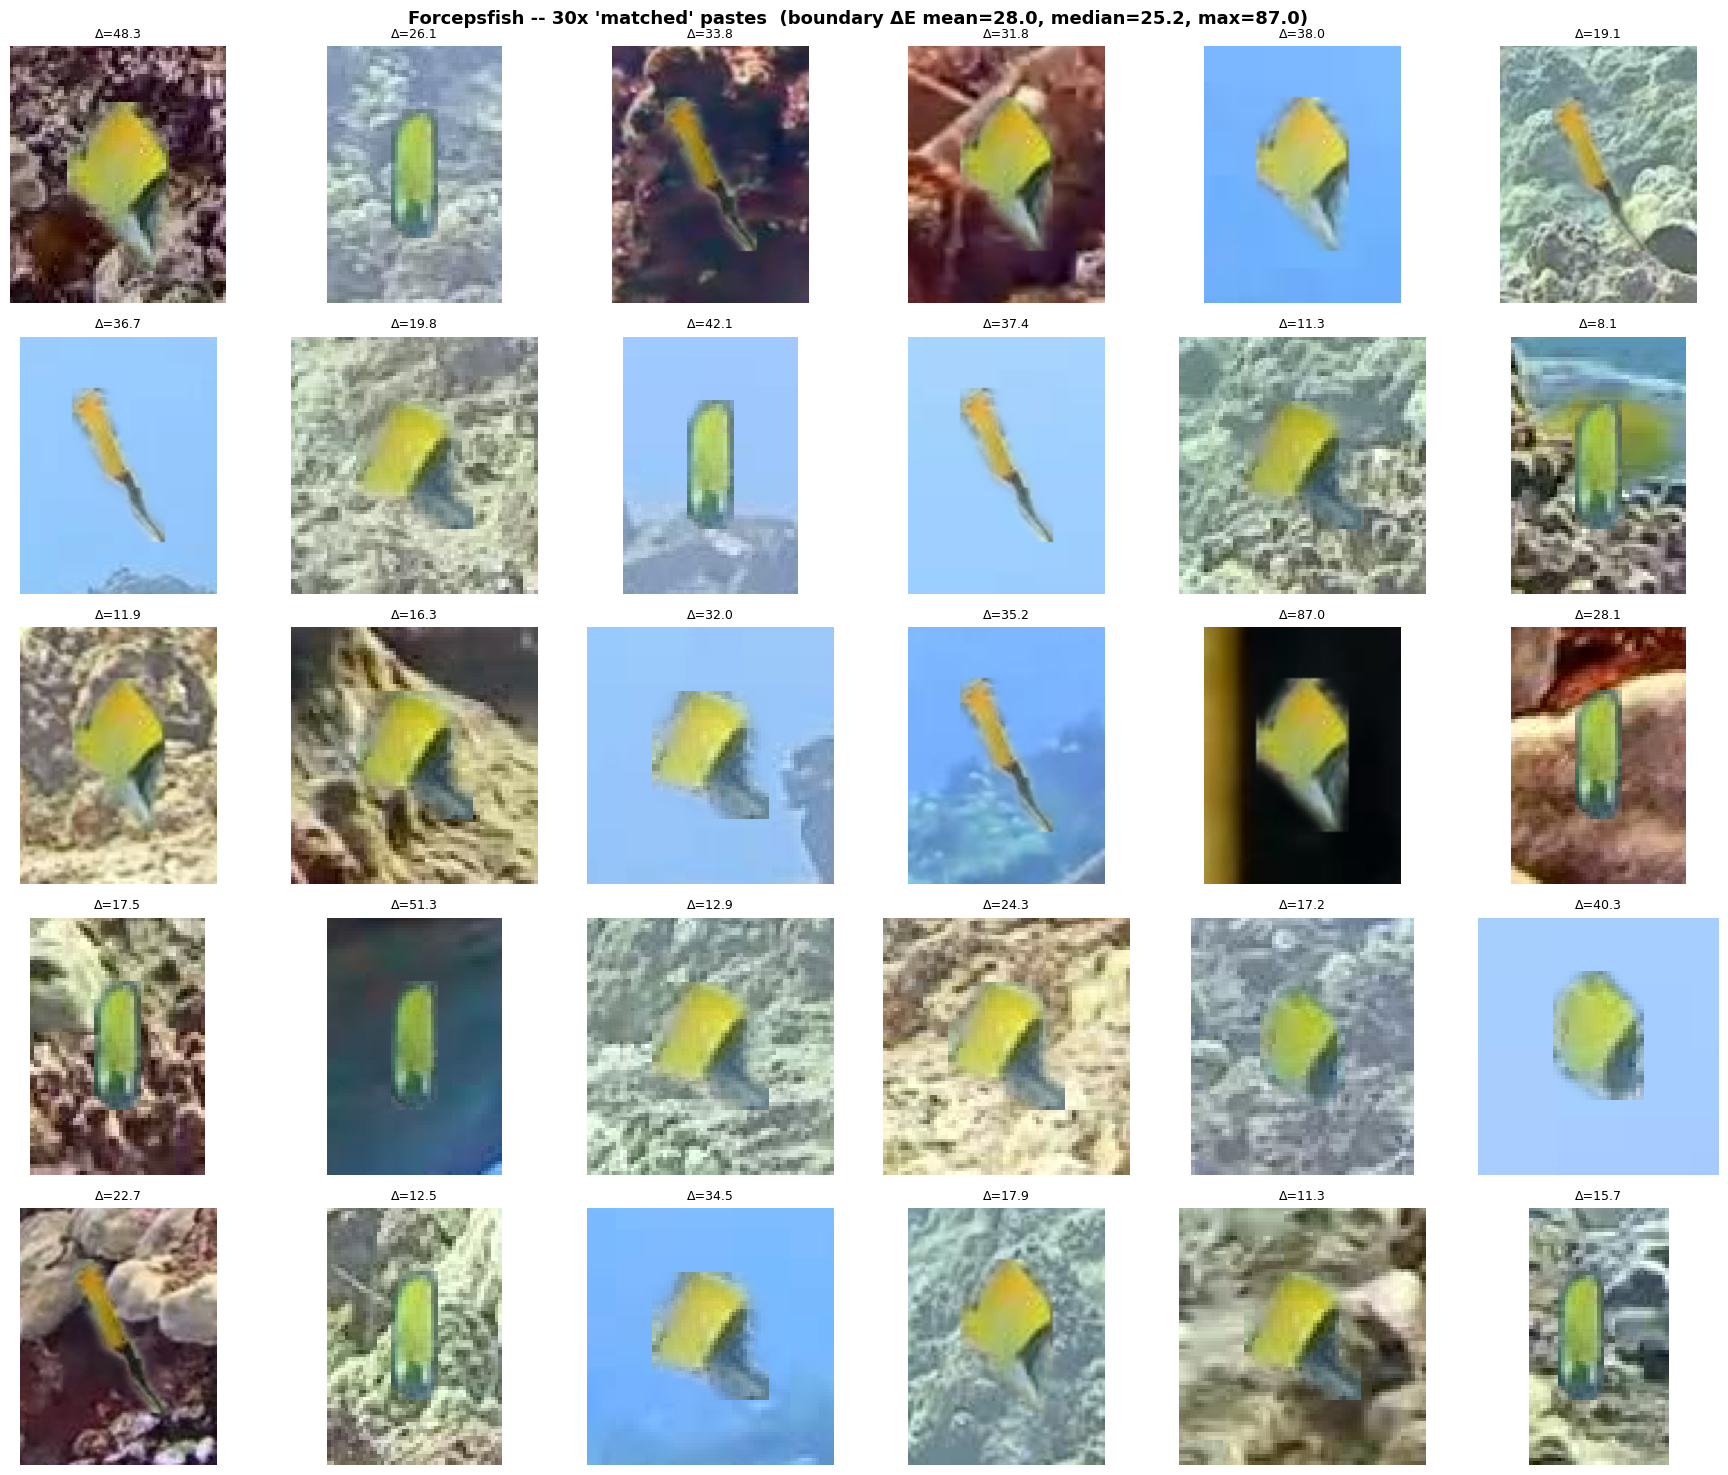

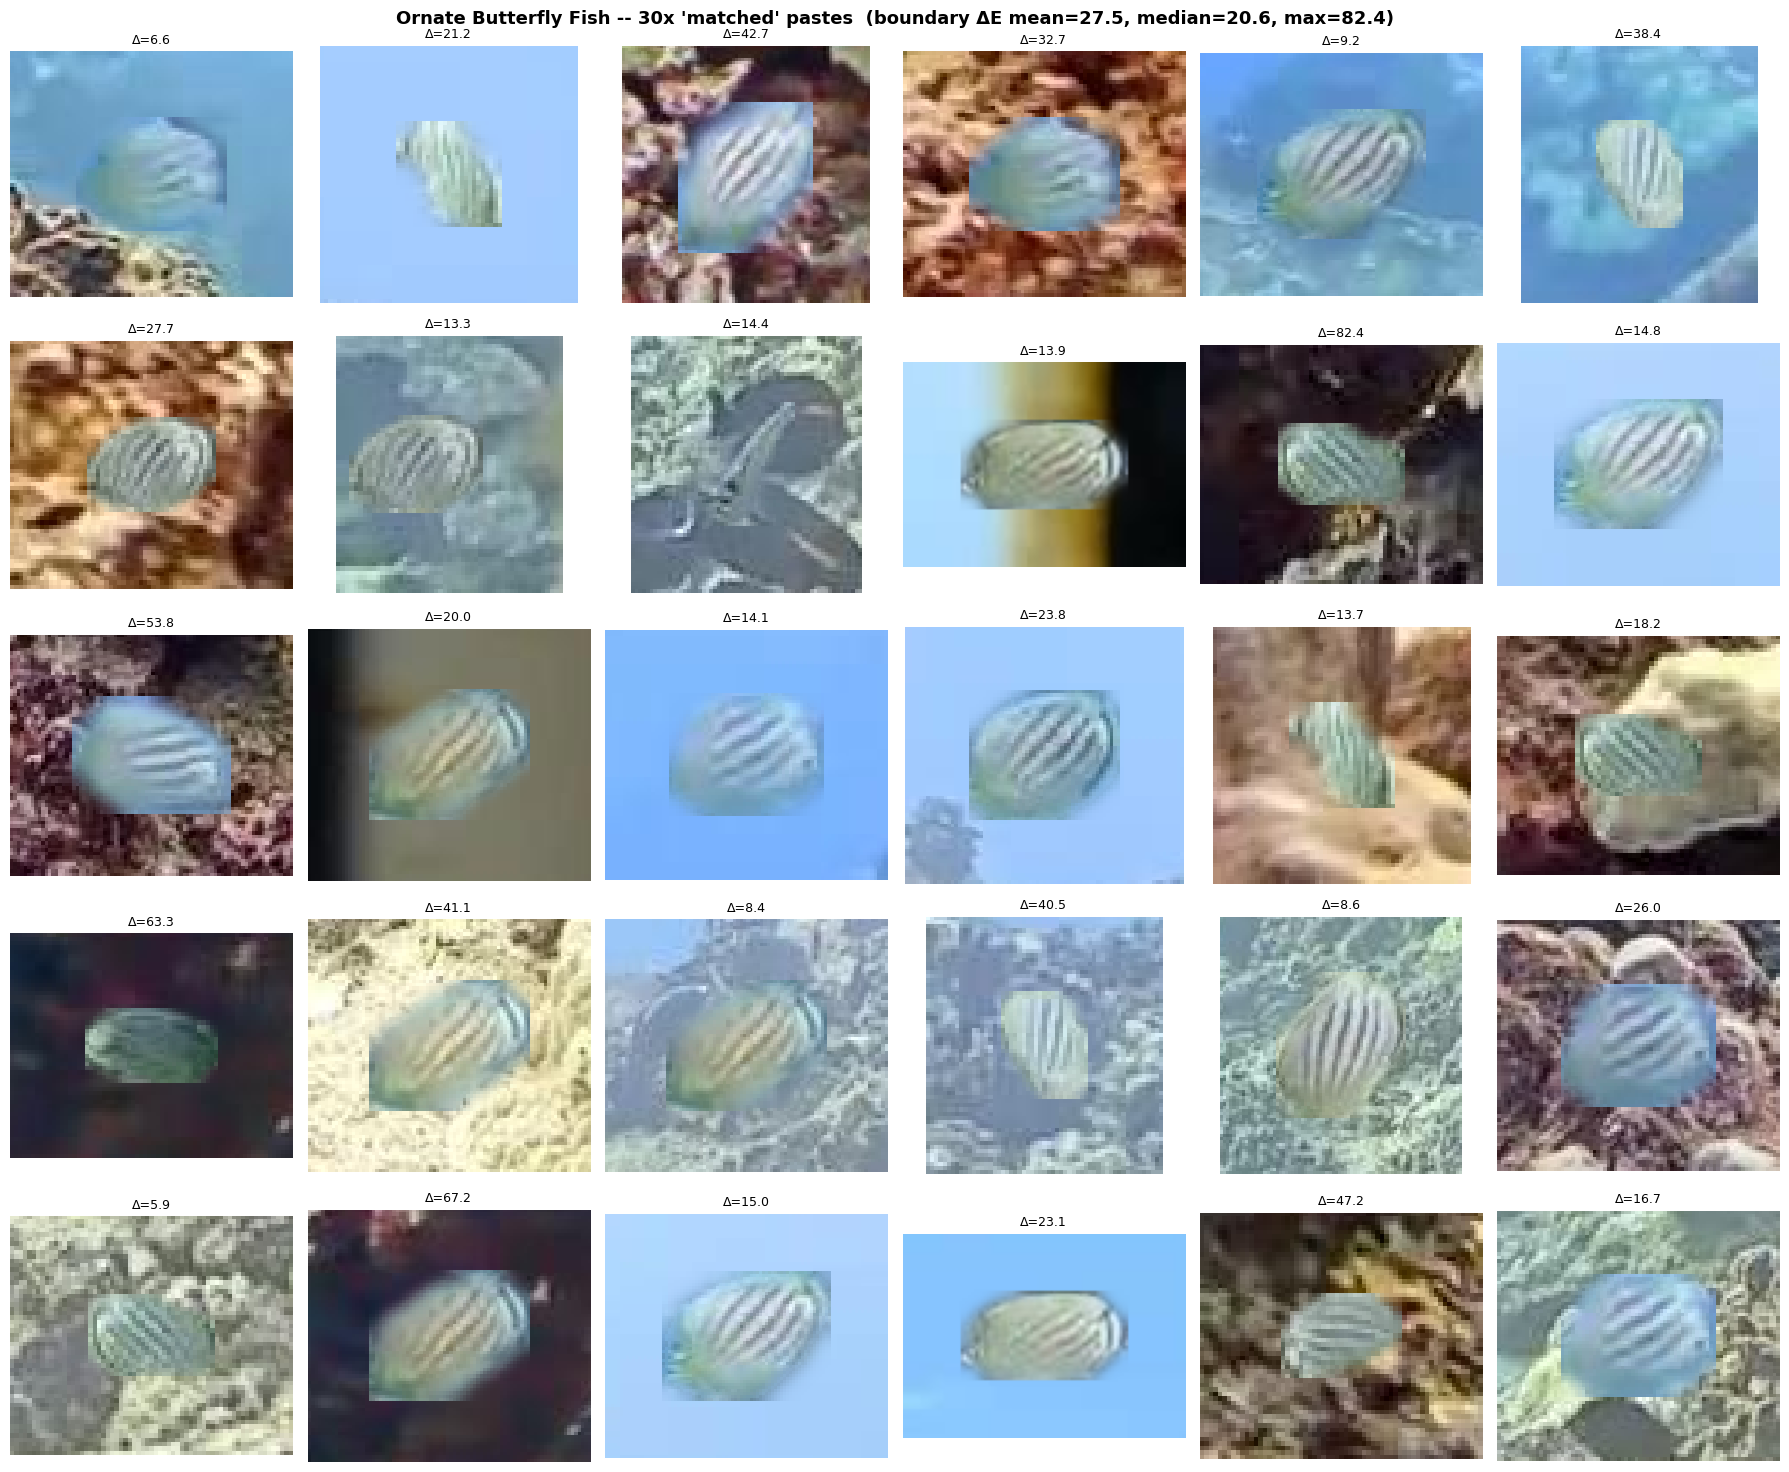

In [13]:
def augmentation_gallery(species: str, n: int = 30, blend: str = "matched", cols: int = 6,
                          seed: int = 0, min_dim: int = 0, tag_suffix: str = ""):
    rng = random.Random(seed)
    donors = eligible_donors(DATASET, species, min_dim=min_dim)
    targets = [(name, d) for name, d in DATASET.items()
               if d["frame"] is not None and d["frame"] >= MIN_FRAME and len(d["instances"]) <= 1]
    if not donors or not targets:
        print(f"Not enough donors/targets for {species}")
        return

    # Prefer donors/targets whose frame is actually on disk, same as the single-example demos
    # above -- otherwise, with partial local coverage, most tiles silently fall back to
    # synthetic placeholders even though real alternatives exist. With the full dataset behind
    # IMAGES_DIR this is a no-op (everything is "local"), so it's safe to always leave in.
    local_donor_frames = {f for _, f in _prefer_locally_available(
        [(name, DATASET[name]["frame"]) for name, _ in donors])}
    donors_local = [nd for nd in donors if DATASET[nd[0]]["frame"] in local_donor_frames]
    donors = donors_local or donors

    local_target_frames = {f for _, f in _prefer_locally_available(
        [(name, d["frame"]) for name, d in targets])}
    targets_local = [(n_, d) for n_, d in targets if d["frame"] in local_target_frames]
    targets = targets_local or targets

    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.0, rows * 3.0))
    axes = np.atleast_2d(axes)

    scores = []
    for i in range(n):
        ax = axes[i // cols][i % cols]
        donor_name, donor_inst = rng.choice(donors)
        target_name, target_d = rng.choice(targets)
        donor_patch, donor_mask = get_donor_patch(donor_name, donor_inst)
        target_img = load_image(target_name, target_d["iw"], target_d["ih"], frame=target_d["frame"])
        existing = [inst["bbox"] for inst in target_d["instances"]]

        mh, mw = donor_mask.shape
        if mh >= target_img.shape[0] or mw >= target_img.shape[1]:
            ax.axis("off")
            continue
        x, y = find_placement(target_img.shape, donor_mask.shape, existing)

        if blend == "naive":
            result = paste_naive(target_img, donor_patch, donor_mask, x, y)
        elif blend == "poisson":
            result = paste_poisson(target_img, donor_patch, donor_mask, x, y)
        else:
            result = paste_matched_feathered(target_img, donor_patch, donor_mask, x, y)

        pad = max(18, int(0.35 * max(mw, mh)))
        cy0, cy1 = max(y - pad, 0), min(y + mh + pad, result.shape[0])
        cx0, cx1 = max(x - pad, 0), min(x + mw + pad, result.shape[1])
        crop = result[cy0:cy1, cx0:cx1]

        # boundary ring score needs the mask in the *crop's* coordinate frame -- clip in case
        # the paste site sits near the image edge and the crop got clamped there
        crop_h, crop_w = crop.shape[:2]
        local_mask = np.zeros((crop_h, crop_w), dtype=np.uint8)
        my0, mx0 = y - cy0, x - cx0
        avail_h, avail_w = min(mh, crop_h - my0), min(mw, crop_w - mx0)
        if avail_h > 0 and avail_w > 0:
            local_mask[my0:my0 + avail_h, mx0:mx0 + avail_w] = donor_mask[:avail_h, :avail_w]
        score = boundary_mismatch_score(crop, local_mask)
        scores.append(score)

        ax.imshow(crop)
        tag = "" if not IS_SYNTHETIC.get(donor_name) and not IS_SYNTHETIC.get(target_name) else " [synthetic]"
        ax.set_title(f"Δ={score:.1f}{tag}", fontsize=9)
        ax.axis("off")

    for j in range(n, rows * cols):
        axes[j // cols][j % cols].axis("off")

    valid_scores = [s for s in scores if not np.isnan(s)]
    size_note = f", min_dim>={min_dim}px" if min_dim else ""
    fig.suptitle(
        f"{species} -- {n}x '{blend}' pastes{size_note}  "
        f"(boundary ΔE mean={np.mean(valid_scores):.1f}, "
        f"median={np.median(valid_scores):.1f}, max={np.max(valid_scores):.1f})",
        fontsize=13, fontweight="bold")
    plt.tight_layout()
    fname = f"gallery_{species.replace(' ', '_')}_{blend}{tag_suffix}.png"
    plt.savefig(fname, dpi=100)
    plt.show()
    return valid_scores


gallery_scores = {}
for sp in CANDIDATE_SPECIES:
    gallery_scores[sp] = augmentation_gallery(sp, n=30, blend="matched")

Reading the grid: `Δ` is the boundary mismatch score from Section 9 -- lower is a
better-blended seam. A `[synthetic]` tag means that particular tile fell back to a
placeholder (Section 13's coverage check explains why); ignore its score, since it's not a
real colour match. If most real tiles cluster under roughly 10-15 with a handful of higher
outliers, that's consistent with `matched` mode doing its job in the normal case while still
occasionally producing a seam worth catching -- which is exactly what a reject/retry gate
(as in `copy_paste_augment.py`) is for. If scores are high and scattered across the board
instead, that would point to a real problem with the blend itself, not just a few hard cases.

If you still see a handful of higher-Δ outliers among small instances in the gallery above,
that's the same mask-shape pattern investigated properly below (Section 11a) -- it isn't
unique to any one species.

## 11. Case study: why Moorish Idol was dropped (and the tools that caught it)

This section is a worked investigation into a species that is **no longer** one of the three
above -- Moorish Idol was tried first, turned out to have real problems, and was replaced
(Section 5). It's kept here in full, rather than deleted, for two reasons: the reasoning is
exactly the kind of methodology a thesis benefits from showing (a hypothesis that turned out
to be wrong, caught and corrected with evidence, not just asserted), and the diagnostic tools
built along the way (11a's shape check, 11b's colour-risk check) get reused in 11d to actually
confirm Forcepsfish and Ornate Butterfly Fish don't have the same problem, rather than just
assuming they don't.

Two separate things turned up while building Moorish Idol's gallery, worth telling apart
rather than lumping into one "it's a bit off sometimes" note: a **shape** issue (a boxy seam
on some small instances) and, found while chasing that, a **colour** issue (dark donors going
pale when pasted onto very flat, bright targets). They have different causes and different
fixes.

### 11a. The boxy seam -- a mask-shape issue, not a blend bug

A few tiles in both galleries above show a faint rectangular "halo" at the seam instead of a
clean fish-shaped edge, and it's tempting to assume that's a feathering bug (too much Gaussian
blur spreading colour outside the true silhouette). That was my first guess too, so I checked
it directly: `feather_px` in `paste_matched_feathered` already scales down for small masks
(Section 6), and tightening it further made the *boundary ΔE score* slightly worse, not
better. That's the opposite of what a blur-radius bug would predict, so something else is
going on.

The real explanation shows up in the CVAT masks themselves, not in the blending code. Below,
every eligible donor mask for both species is decoded and scored for two things: `coverage`
(mask area / bounding-box area -- a box-filling silhouette scores near 1.0, a slender fish
shape scores much lower) and `n_vertices` (corners in a simplified silhouette outline --
roughly, how much real fin/tail/body detail survived annotation). Both are plotted against
the fish's pixel size (`min_dim`, the shorter side of its bounding box).

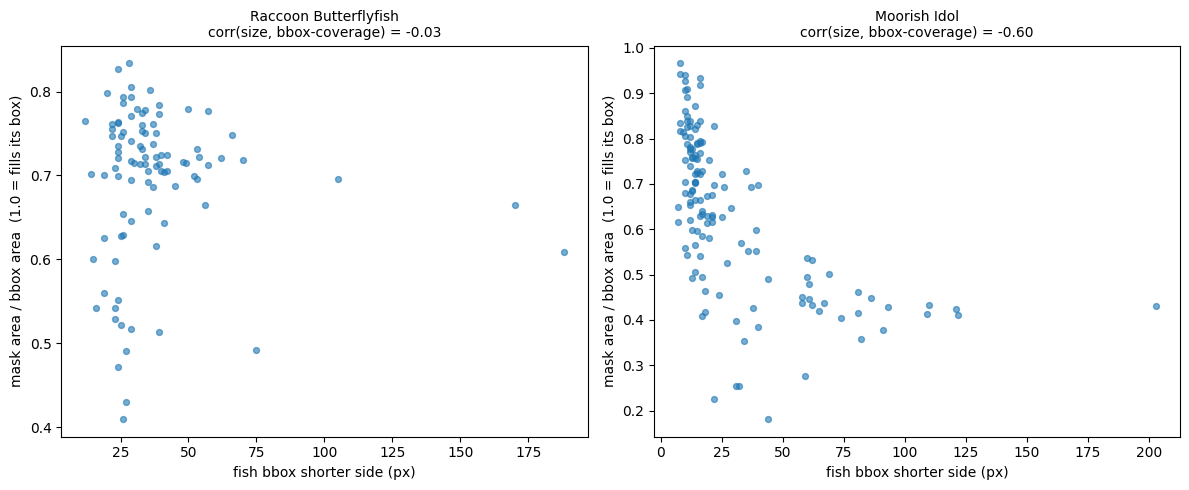


Raccoon Butterflyfish: n=95 eligible donors
  smallest 5 by bbox size -- mean coverage 0.66, mean n_vertices 7.6
  largest  5 by bbox size -- mean coverage 0.64, mean n_vertices 8.6

Moorish Idol: n=135 eligible donors
  smallest 5 by bbox size -- mean coverage 0.80, mean n_vertices 7.2
  largest  5 by bbox size -- mean coverage 0.42, mean n_vertices 9.2


In [14]:
def mask_shape_diagnostics(dataset: dict, species: str) -> pd.DataFrame:
    """Decode every eligible donor mask for `species` and score its shape complexity."""
    rows = []
    for name, inst in eligible_donors(dataset, species):
        left, top, w, h = inst["bbox"]
        mask = decode_cvat_rle(inst["rle"], w, h)
        area = int(mask.sum())
        coverage = area / (w * h) if w * h else np.nan
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        n_vertices = np.nan
        if contours:
            c = max(contours, key=cv2.contourArea)
            perim = cv2.arcLength(c, True)
            if perim > 0:
                n_vertices = len(cv2.approxPolyDP(c, 0.02 * perim, True))
        rows.append({"name": name, "min_dim": min(w, h), "area": area,
                      "coverage": coverage, "n_vertices": n_vertices})
    return pd.DataFrame(rows).sort_values("min_dim").reset_index(drop=True)


def print_mask_ascii(dataset: dict, name: str, inst: dict):
    left, top, w, h = inst["bbox"]
    mask = decode_cvat_rle(inst["rle"], w, h)
    print(f"{name}  bbox={inst['bbox']}  coverage={mask.sum() / (w * h):.2f}")
    for row in mask:
        print("".join("#" if v else "." for v in row))
    print()


# This case study compares Raccoon Butterflyfish (clean baseline) against Moorish Idol (the
# species that failed) -- deliberately NOT CANDIDATE_SPECIES, which by this point in the
# notebook has already moved on to the three species actually being used (Section 5).
CASE_STUDY_SPECIES = ["Raccoon Butterflyfish", "Moorish Idol"]

shape_dfs = {sp: mask_shape_diagnostics(DATASET, sp) for sp in CASE_STUDY_SPECIES}

fig, axes = plt.subplots(1, len(CASE_STUDY_SPECIES), figsize=(6 * len(CASE_STUDY_SPECIES), 5))
axes = np.atleast_1d(axes)
for ax, sp in zip(axes, CASE_STUDY_SPECIES):
    df = shape_dfs[sp]
    ax.scatter(df["min_dim"], df["coverage"], s=18, alpha=0.6)
    corr = df["min_dim"].corr(df["coverage"])
    ax.set_title(f"{sp}\ncorr(size, bbox-coverage) = {corr:.2f}", fontsize=10)
    ax.set_xlabel("fish bbox shorter side (px)")
    ax.set_ylabel("mask area / bbox area  (1.0 = fills its box)")
plt.tight_layout()
plt.savefig("mask_shape_vs_size.png", dpi=110)
plt.show()

for sp in CASE_STUDY_SPECIES:
    df = shape_dfs[sp]
    print(f"\n{sp}: n={len(df)} eligible donors")
    print(f"  smallest 5 by bbox size -- mean coverage {df.head(5)['coverage'].mean():.2f}, "
          f"mean n_vertices {df.head(5)['n_vertices'].mean():.1f}")
    print(f"  largest  5 by bbox size -- mean coverage {df.tail(5)['coverage'].mean():.2f}, "
          f"mean n_vertices {df.tail(5)['n_vertices'].mean():.1f}")

**The two species don't tell quite the same story, and that's worth sitting with rather than
flattening into one conclusion:**

- **Moorish Idol**: corr(size, coverage) = -0.60. A clear, fairly strong trend -- the smallest
  donor instances really do have boxier masks than the larger ones. This is the species to
  expect the occasional "halo" tile from.
- **Raccoon Butterflyfish**: corr(size, coverage) = -0.03. Essentially no trend -- this
  species' small donors aren't systematically boxier than its large ones. That's consistent
  with the Raccoon Butterflyfish demo looking clean: it's not that this species got lucky,
  its mask quality genuinely doesn't degrade much with size in this export.

The ASCII dumps below make the Moorish Idol pattern concrete: a small, boxy donor next to a
larger, more fish-shaped one from the same species.

In [15]:
mi_df = shape_dfs["Moorish Idol"]
mi_donors = dict(eligible_donors(DATASET, "Moorish Idol"))
for _, row in pd.concat([mi_df.head(1), mi_df.tail(1)]).iterrows():
    print_mask_ascii(DATASET, row["name"], mi_donors[row["name"]])

nelha-trimmed_mp4-1046_jpg.rf.981d4833ac7af08523e3f91fc641fe62.jpg  bbox=(491, 351, 7, 20)  coverage=0.65
###....
###....
###....
###....
####...
####...
#####..
.####..
.#####.
..####.
..#####
...####
...####
...####
...####
..#####
#######
#######
#######
######.

nelha-trimmed_mp4-2381_jpg.rf.c6fb8f289ff7baf615c045f6e544f702.jpg  bbox=(468, 391, 204, 203)  coverage=0.43
.......................................................................................................#########################.#..........................................................................
.....................................................................................................#################################......................................................................
.................................................................................................#.#######################################..................................................................
.........

**What this means for the gallery:** feathering was never hiding this -- it was, if anything,
smoothing it over. The tighter the paste hugs the true mask, the more visible the mask's own
blockiness becomes at the seam, which is exactly the slight regression seen when the feather
radius was tightened for small instances. The label itself (Section 8) is still exactly this
mask, feathered or not, so nothing here is a mislabelling risk -- it's a resolution limit on
*how precisely* the smallest donors' true outline was ever captured.

**What to actually do about it is your call, not a default I've baked in -- and the right
call may genuinely differ by species, given the correlation split above:**
- Leave it as-is. A handful of blockier small-fish pastes is a realistic property of this
  dataset (distant/small real fish are blurry and hard to segment precisely too), and the
  `matched`-mode colour correction still holds the body tone close regardless of edge shape.
- Add a minimum donor size (e.g. `min_dim >= 20px`) to `eligible_donors()` before running the
  real augmentation sweep. The table below shows the actual cost of that per species: for
  Raccoon Butterflyfish it's nearly free (keeps ~93% of donors, since size barely predicts
  mask quality there); for Moorish Idol it's a real trade -- you'd lose well over half the
  donor pool to buy cleaner seams, which may or may not be worth it next to just having more
  paste variety.

In [16]:
for sp in CASE_STUDY_SPECIES:
    df = shape_dfs[sp]
    total = len(df)
    for min_dim_thresh in (15, 20, 25):
        kept = (df["min_dim"] >= min_dim_thresh).sum()
        print(f"{sp}: min_dim >= {min_dim_thresh}px keeps {kept}/{total} donors "
              f"({kept / total:.0%})" if total else f"{sp}: no eligible donors")

Raccoon Butterflyfish: min_dim >= 15px keeps 93/95 donors (98%)
Raccoon Butterflyfish: min_dim >= 20px keeps 88/95 donors (93%)
Raccoon Butterflyfish: min_dim >= 25px keeps 71/95 donors (75%)
Moorish Idol: min_dim >= 15px keeps 83/135 donors (61%)
Moorish Idol: min_dim >= 20px keeps 54/135 donors (40%)
Moorish Idol: min_dim >= 25px keeps 44/135 donors (33%)


### 11b. High-contrast donors going pale against lower-contrast targets

This is the one that actually explains the Black Triggerfish colour problem that started this
whole investigation: a `naive` paste keeps a donor's true near-black bands, but a `feathered +
colour-matched` paste of the same donor can come out noticeably paler and hazier across its
*whole* body, not just at the seam -- the worked example below (11c) shows this directly for
Moorish Idol.

My first theory was "rare edge case: donor lands on flat open water." Checking that
properly -- by measuring local texture at the *actual* paste site for many real (donor,
target) pairs, not just eyeballing one demo frame -- showed that theory was wrong in an
important way: **it's not really about rare flat water. It's that Moorish Idol's own
black/white/yellow banding has far more internal contrast than *most* reef backgrounds have
texture**, so the colour-matching code sees almost every target as comparatively "flat" next
to this particular donor, not just open-water ones.

In [17]:
def local_contrast_ratios(species: str, n: int = 60, seed: int = 1) -> np.ndarray:
    """For n random real (donor, target) pairs, the ratio of target-patch-std to donor-std in
    the L channel at the actual paste site -- this is exactly what color_transfer_lab's
    std_ratio term sees. A ratio << 1 means the target has much less local texture than the
    donor has contrast, which is the condition that risks washing the donor out."""
    donors = eligible_donors(DATASET, species)
    donor_frames = {f for _, f in _prefer_locally_available(
        [(name, DATASET[name]["frame"]) for name, _ in donors])}
    donors_local = [nd for nd in donors if DATASET[nd[0]]["frame"] in donor_frames]

    targets = [(name, d) for name, d in DATASET.items()
               if d["frame"] is not None and d["frame"] >= MIN_FRAME and len(d["instances"]) <= 1]
    target_frames = {f for _, f in _prefer_locally_available([(n_, d["frame"]) for n_, d in targets])}
    targets_local = [(n_, d) for n_, d in targets
                      if d["frame"] in target_frames and not IS_SYNTHETIC.get(n_)]

    rng = random.Random(seed)
    ratios = []
    for _ in range(n):
        if not donors_local or not targets_local:
            break
        donor_name, donor_inst = rng.choice(donors_local)
        target_name, target_d = rng.choice(targets_local)
        donor_patch, donor_mask = get_donor_patch(donor_name, donor_inst)
        target_img = load_image(target_name, target_d["iw"], target_d["ih"], frame=target_d["frame"])
        mh, mw = donor_mask.shape
        if mh >= target_img.shape[0] or mw >= target_img.shape[1]:
            continue
        existing = [inst["bbox"] for inst in target_d["instances"]]
        x, y = find_placement(target_img.shape, donor_mask.shape, existing)
        local_bg_lab = cv2.cvtColor(target_img[y:y + mh, x:x + mw], cv2.COLOR_RGB2LAB).astype(np.float32)
        patch_lab = cv2.cvtColor(donor_patch, cv2.COLOR_RGB2LAB).astype(np.float32)
        src_std = patch_lab[:, :, 0][donor_mask.astype(bool)].std() + 1e-6
        ratios.append(local_bg_lab[:, :, 0].std() / src_std)
    return np.array(ratios)


mi_ratios = local_contrast_ratios("Moorish Idol")
rbf_ratios = local_contrast_ratios("Raccoon Butterflyfish")
for sp, ratios in [("Moorish Idol", mi_ratios), ("Raccoon Butterflyfish", rbf_ratios)]:
    if len(ratios) == 0:
        print(f"{sp}: not enough local donors/targets to sample -- skipped")
        continue
    print(f"{sp}: n={len(ratios)} real (donor, target) pairs sampled "
          f"(from locally-staged frames only, not the full dataset)")
    print(f"  target/donor local-contrast ratio -- median {np.median(ratios):.2f}, "
          f"fraction < 0.3 (high wash-out risk): {(ratios < 0.3).mean():.0%}")

Moorish Idol: n=60 real (donor, target) pairs sampled (from locally-staged frames only, not the full dataset)
  target/donor local-contrast ratio -- median 0.45, fraction < 0.3 (high wash-out risk): 40%
Raccoon Butterflyfish: n=60 real (donor, target) pairs sampled (from locally-staged frames only, not the full dataset)
  target/donor local-contrast ratio -- median 0.61, fraction < 0.3 (high wash-out risk): 35%


**Reading this:** for Moorish Idol, a large share of realistic pairings land in the
high-risk zone -- this is a real, fairly common characteristic of pasting *this* species, not
a one-off bad draw. Raccoon Butterflyfish's own colours are much less extreme (it doesn't have
Moorish Idol's stark black/white banding), so the same mechanism bites it far less often --
consistent with its demo and gallery looking clean. That split lines up with Section 11a's
correlation split too: Moorish Idol is the more failure-prone species here on both shape and
colour grounds. **One caveat before reading too much into "just its own high-contrast
colouring vs. the background"** -- this diagnostic treats every donor's own contrast as a
fixed, correct fact about the fish and blames the mismatch entirely on the target. Section 11c
complicates that: it turns out a lot of the *donor's own* apparent low contrast, for the
smallest instances specifically, is itself a data characteristic (likely real underwater
colour attenuation on distant fish), not just "this fish is naturally bold." Keep that in mind
through the rest of this section -- the full picture needs both pieces.

Given that, `color_transfer_lab` now also caps how far the mean-brightness term can shift a
channel, relative to the donor's own spread (Section 6) -- not just the contrast-matching term
clamped earlier. The cell below checks a real Moorish Idol worst-case donor/target pairing
with both guards in place, so you can see the actual improvement rather than taking it on
faith.

In [18]:
def colour_shift_report(patch: np.ndarray, mask: np.ndarray, target_region: np.ndarray):
    patch_lab = cv2.cvtColor(patch, cv2.COLOR_RGB2LAB).astype(np.float32)
    matched = color_transfer_lab(patch, mask, target_region)
    matched_lab = cv2.cvtColor(matched, cv2.COLOR_RGB2LAB).astype(np.float32)
    m = mask.astype(bool)
    print(f"{'channel':>8} {'src mean':>9} {'out mean':>9} {'src std':>8} {'out std':>8}")
    for c, name in enumerate(["L", "a", "b"]):
        sv, ov = patch_lab[:, :, c][m], matched_lab[:, :, c][m]
        print(f"{name:>8} {sv.mean():9.1f} {ov.mean():9.1f} {sv.std():8.1f} {ov.std():8.1f}")
    darkest_before = np.percentile(patch_lab[:, :, 0][m], 5)
    darkest_after = np.percentile(matched_lab[:, :, 0][m], 5)
    print(f"\ndarkest 5% of donor pixels (L channel): {darkest_before:.0f} -> {darkest_after:.0f} "
          f"after matching (0=black, 255=white)")


mi_donors_list = eligible_donors(DATASET, "Moorish Idol")
mi_local_frames = {f for _, f in _prefer_locally_available(
    [(n, DATASET[n]["frame"]) for n, _ in mi_donors_list])}
mi_donors_local = [nd for nd in mi_donors_list if DATASET[nd[0]]["frame"] in mi_local_frames]
demo_donor_name, demo_donor_inst = max(mi_donors_local, key=lambda nd: nd[1]["bbox"][2] * nd[1]["bbox"][3])
demo_donor_patch, demo_donor_mask = get_donor_patch(demo_donor_name, demo_donor_inst)

# the flat, bright patch standing in for an open-water target -- close to the worst case for
# this donor given how dark/high-contrast it is
flat_bright_target = np.tile(np.array([173, 209, 237], dtype=np.uint8),
                              (demo_donor_mask.shape[0], demo_donor_mask.shape[1], 1))
colour_shift_report(demo_donor_patch, demo_donor_mask, flat_bright_target)

# is `poisson` a safer fallback for this donor? check directly rather than assume --
# seamlessClone needs margin around the mask, so pad the flat target out and centre the paste
pad = 25
mh, mw = demo_donor_mask.shape
poisson_target = np.tile(np.array([173, 209, 237], dtype=np.uint8), (mh + 2 * pad, mw + 2 * pad, 1))
poisson_result = paste_poisson(poisson_target, demo_donor_patch, demo_donor_mask, pad, pad)
poisson_crop_lab = cv2.cvtColor(poisson_result[pad:pad + mh, pad:pad + mw], cv2.COLOR_RGB2LAB).astype(np.float32)
m = demo_donor_mask.astype(bool)
matched_lab_check = cv2.cvtColor(color_transfer_lab(demo_donor_patch, demo_donor_mask, flat_bright_target),
                                  cv2.COLOR_RGB2LAB).astype(np.float32)
true_lab_check = cv2.cvtColor(demo_donor_patch, cv2.COLOR_RGB2LAB).astype(np.float32)
print(f"\npoisson result on the same worst-case pairing -- darkest 5% of donor pixels (L): "
      f"{np.percentile(poisson_crop_lab[:, :, 0][m], 5):.0f} "
      f"(guarded matched was {np.percentile(matched_lab_check[:, :, 0][m], 5):.0f}, "
      f"true value was {np.percentile(true_lab_check[:, :, 0][m], 5):.0f})")

 channel  src mean  out mean  src std  out std
       L     147.8     173.3     77.7     68.3
       a     121.0     121.4      7.1      5.9
       b     143.8     138.0     19.6     18.1

darkest 5% of donor pixels (L channel): 40 -> 77 after matching (0=black, 255=white)

poisson result on the same worst-case pairing -- darkest 5% of donor pixels (L): 121 (guarded matched was 77, true value was 40)


Even with both guards, a dark donor pasted onto a genuinely flat, bright target still comes
out somewhat lighter than its true colour -- that's expected: the guards *bound* the damage,
they don't promise a perfect match regardless of how mismatched donor and target are, and
shouldn't be tightened further without a reason, since that would start eating into the normal
case that's already working well (the galleries above).

**An honest trade-off, not a free fix:** tightening these guards to hold onto the donor's true
colour comes at a real cost elsewhere -- Moorish Idol's own gallery (11c below) with these
guards in place scored *worse* on boundary ΔE (Section 9) on average, not better (the exact
before/after numbers are in each gallery's title). That's not a bug in
either check, it's the two goals genuinely pulling in opposite directions for a high-contrast
donor on a mismatched target: holding the donor closer to its *own* true colour necessarily
means blending *less* smoothly into a background that colour doesn't naturally belong against.
There's no parameter choice that wins both at once here -- only where to sit on that trade-off,
which is a judgement call rather than something to keep tuning blind. I've kept the stronger
guard (truer colour, a rougher seam on the worst pairings) since a visibly wrong fish colour
seemed the bigger risk to the report than a soft edge, but it's a reasonable place to disagree.

**What this means practically:**
- For Raccoon Butterflyfish, the same risk shows up less often (its own contrast is typically
  close to a reef background's, not far beyond it) but it's not zero -- worth a glance at its
  gallery too, just with less urgency than Moorish Idol's.
- For Moorish Idol, it's worth actually looking at the `matched`-mode gallery tiles for this
  species before trusting them wholesale in the real augmentation run (Section 9's `[synthetic]`
  tags aside) -- a `naive` paste may read as more faithful for this specific species' highest-
  contrast donors, even though `matched` is the more realistic choice in general (Section 6).
  `poisson` is *not* a good fallback here: the check just above showed the same washing,
  worse if anything, since `cv2.seamlessClone` has none of `color_transfer_lab`'s guards.
- This is also the strongest candidate explanation for the dropped Black Triggerfish result
  (not shown here -- it was dropped before this notebook's species-screening step existed, see
  Section 5): a near-black species run through the same mechanism, likely worse, since it
  starts even darker than Moorish Idol's black bands.

### 11c. Does a size filter or a blend-mode switch actually fix it?

Rather than guess, both levers get tested directly here, specifically for Moorish Idol, since
that's the species actually showing the problem: a fresh `matched` gallery as a baseline, then
the same donors restricted to `min_dim >= 20px` (Section 11a's size filter, still `matched`
blend), then the full donor pool again with `blend="naive"` instead. Comparing the three tells
you which lever is actually doing the work, instead of assuming.

Baseline -- matched, no size filter:


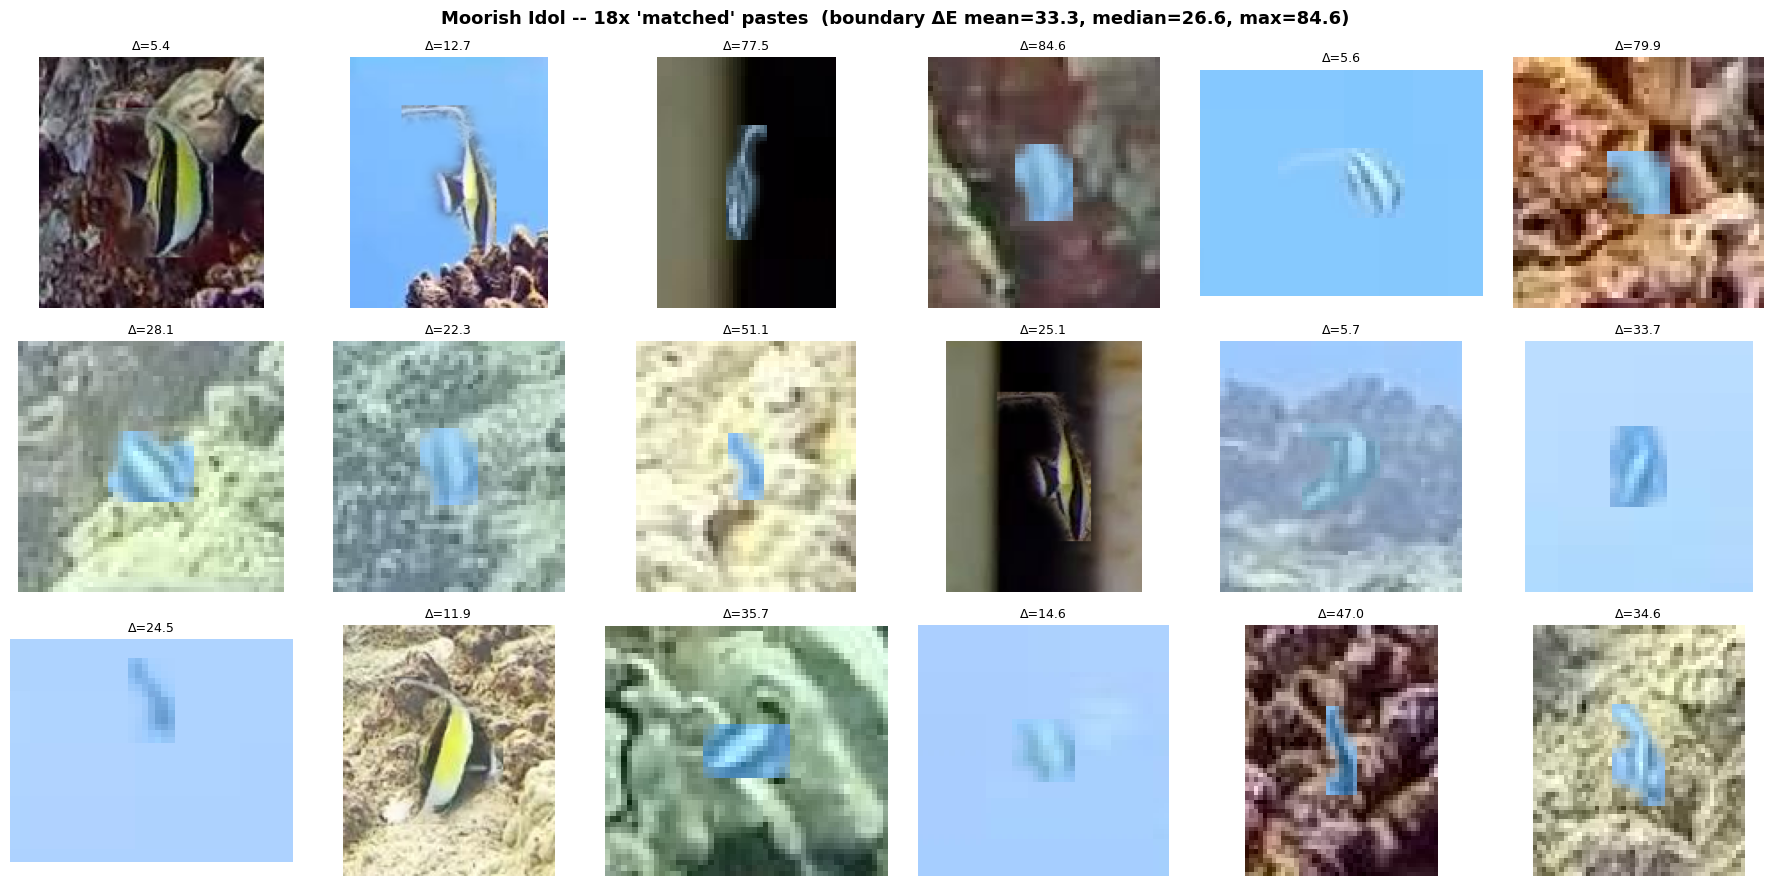


Size-filtered -- matched, min_dim >= 20px:


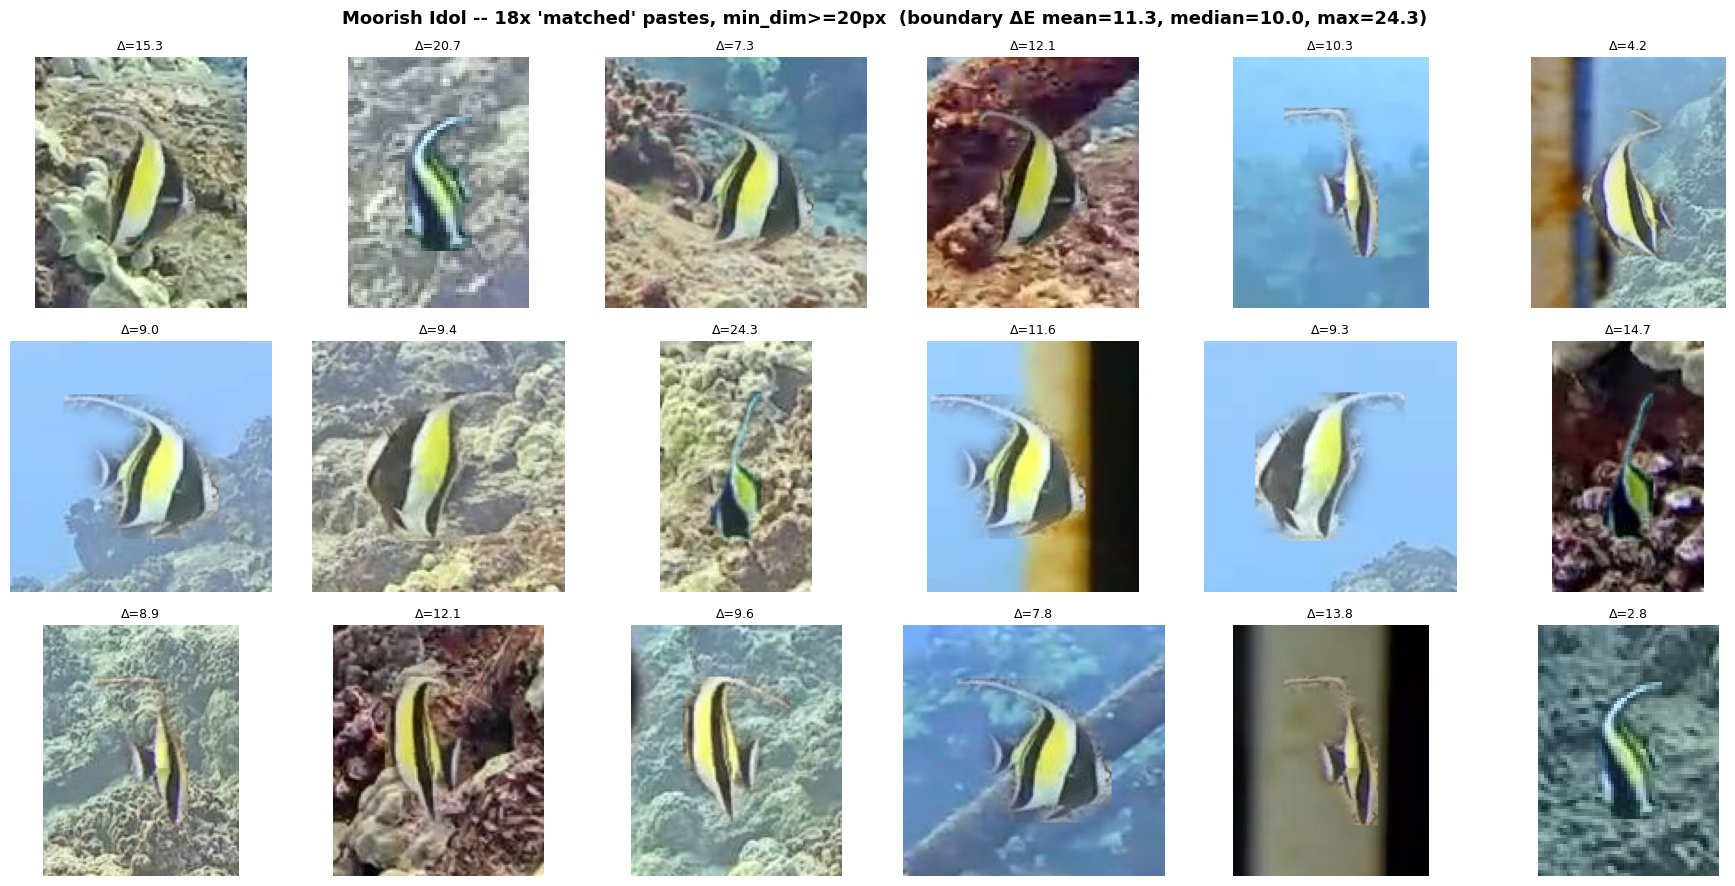


Blend-switched -- naive, no size filter:


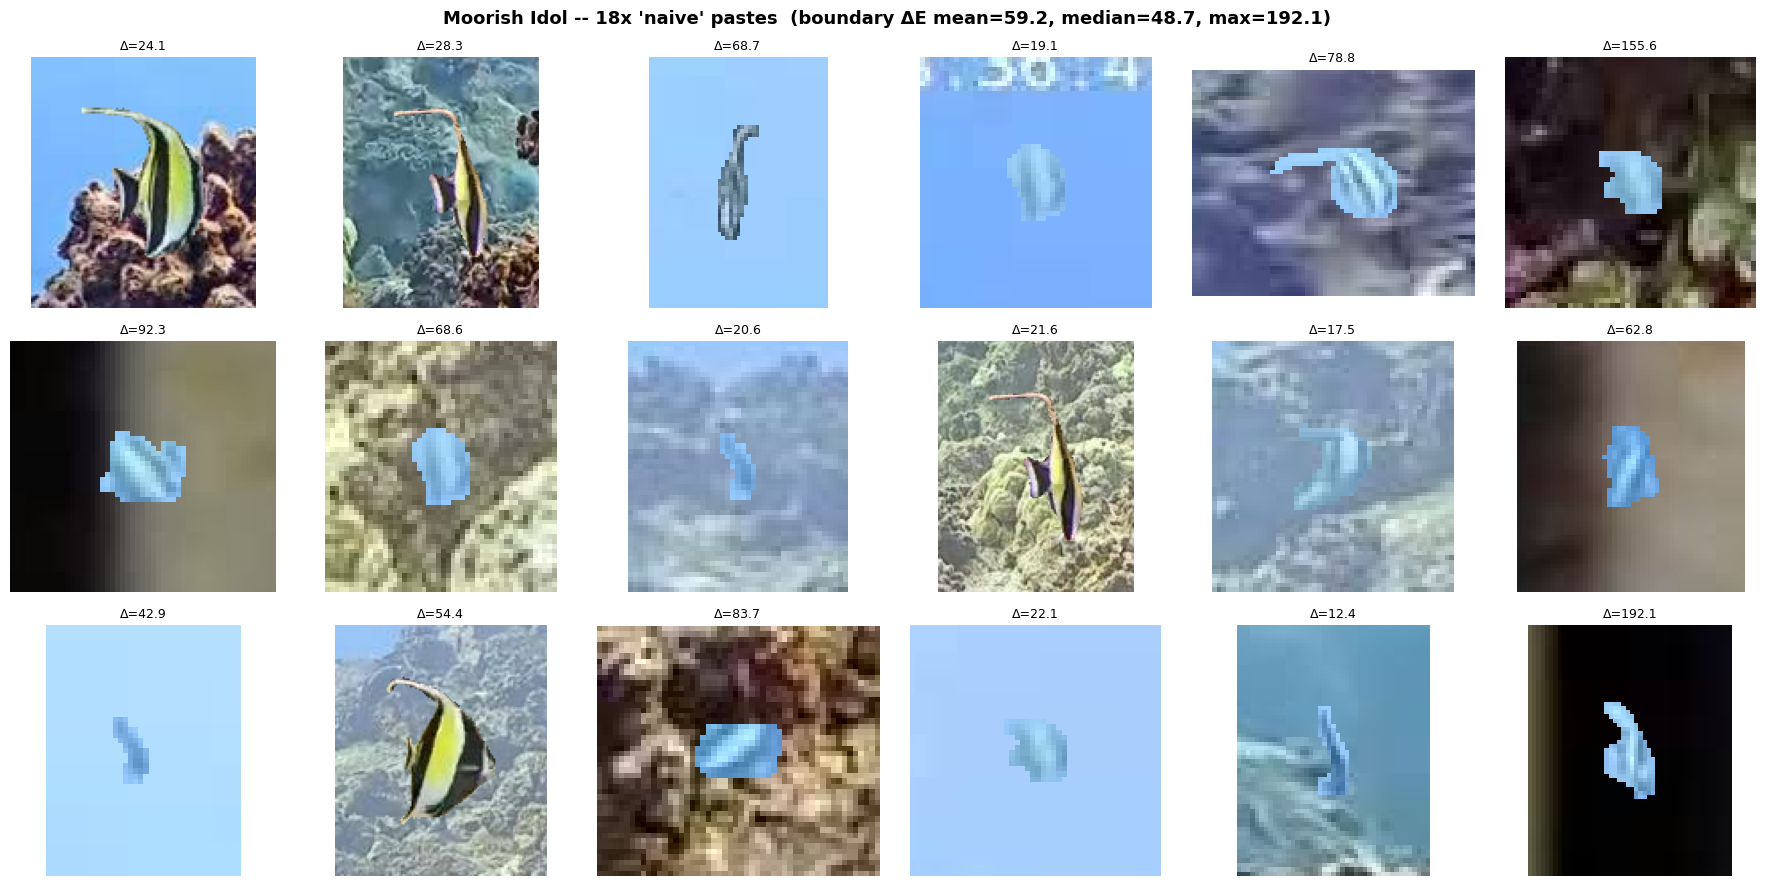

In [19]:
print("Baseline -- matched, no size filter:")
_ = augmentation_gallery("Moorish Idol", n=18, blend="matched", cols=6, tag_suffix="_baseline")

print("\nSize-filtered -- matched, min_dim >= 20px:")
_ = augmentation_gallery("Moorish Idol", n=18, blend="matched", cols=6, min_dim=20, tag_suffix="_sizefiltered")

print("\nBlend-switched -- naive, no size filter:")
_ = augmentation_gallery("Moorish Idol", n=18, blend="naive", cols=6, tag_suffix="_naive")

**Reading this actually overturns part of Section 11b's conclusion, so it's worth saying
plainly rather than quietly patching over it:**

- The size-filtered grid looks *dramatically* cleaner than the baseline -- not a marginal
  improvement. That contradicts what Section 11b's correlation-based argument predicted.
- The naive grid, which does **zero** colour processing, still shows plenty of pale, washed
  blue blobs. If pasting with no colour correction at all still produces hazy blue fish, the
  haze can't be coming from `color_transfer_lab` -- it has to already be sitting in the donor
  crop's own raw pixels.

That second point is the real finding: it points away from the blend code and toward the
*source footage itself*. The cell below checks it directly -- no blending at all, just the raw
LAB statistics of small vs. large donor crops as CVAT cropped them.

In [20]:
def donor_raw_stats(species: str, n_each: int = 6):
    donors = eligible_donors(DATASET, species)
    local_frames = {f for _, f in _prefer_locally_available(
        [(name, DATASET[name]["frame"]) for name, _ in donors])}
    donors_local = [nd for nd in donors if DATASET[nd[0]]["frame"] in local_frames]
    donors_local.sort(key=lambda nd: min(nd[1]["bbox"][2], nd[1]["bbox"][3]))

    rows = []
    for group, subset in [("smallest", donors_local[:n_each]), ("largest", donors_local[-n_each:])]:
        for name, inst in subset:
            patch, mask = get_donor_patch(name, inst)
            lab = cv2.cvtColor(patch, cv2.COLOR_RGB2LAB).astype(np.float32)
            m = mask.astype(bool)
            rows.append({
                "group": group, "min_dim": min(inst["bbox"][2], inst["bbox"][3]),
                "L_mean": lab[:, :, 0][m].mean(), "L_std": lab[:, :, 0][m].std(),
                "b_mean": lab[:, :, 2][m].mean(),  # LAB b: low = blue-shifted, high = yellow
            })
    return pd.DataFrame(rows)


mi_raw = donor_raw_stats("Moorish Idol")
print(mi_raw.groupby("group")[["min_dim", "L_mean", "L_std", "b_mean"]].mean().round(1))
print("\n(b_mean is the LAB blue<->yellow axis: ~128 is neutral, lower is blue-shifted. "
      "L_std is the donor's OWN internal contrast -- Moorish Idol's true banding is high-contrast.)")

          min_dim      L_mean      L_std  b_mean
group                                           
largest      69.2  144.800003  75.300003   144.0
smallest      9.5  170.699997  27.299999   105.5

(b_mean is the LAB blue<->yellow axis: ~128 is neutral, lower is blue-shifted. L_std is the donor's OWN internal contrast -- Moorish Idol's true banding is high-contrast.)


**This is the decisive evidence, not just a visual impression:** small Moorish Idol donors
aren't just annotated coarsely (Section 11a) -- their raw, unprocessed pixels are themselves
blue-shifted and low-contrast compared to the large donors, *before any blending touches them*.
That matches classic underwater colour attenuation on a small/distant subject (blue light
travels farther through water than red/yellow, so a fish far enough from the camera to only
occupy a small bounding box is already photographed hazy and blue-tinted) -- not a processing
bug, and not something any blend mode can recover, since the information genuinely isn't
there in the source crop.

**Revised picture, now that both pieces of evidence are in:**
- Most of what makes the *unfiltered* gallery look bad is small donors that were already poor
  source material going in -- `naive` doesn't fix these because there's nothing to fix at the
  blend level.
- `color_transfer_lab`'s mean-shift mechanism (Section 11b) is still real and still
  demonstrable (11b's own worked example: a large, 87x81px, genuinely vivid donor visibly
  paled under `matched`) -- it's just a smaller contributor than source-quality once you're
  only looking at the large donors, since `min_dim >= 20px` already removes most of the worst
  cases before the blend even runs.

**Revised recommendation:** a size filter (Section 11a, e.g. `min_dim >= 20px`) is the
higher-leverage fix for Moorish Idol, not a minor cleanup on the side -- apply it. On top of
that filtered, already-decent donor pool, `naive` vs `matched` is a smaller, second-order
choice; `matched` is still the more realistic default in general (Raccoon Butterflyfish shows
no reason to deviate from it), but for Moorish Idol's surviving large donors it's worth a
final visual check between the two before committing, since Section 11b's washing mechanism
can still reach even a good donor on an unlucky target.

### 11d. Checking Forcepsfish and Ornate Butterfly Fish against the same tests

Section 5 screened these two in on donor count and median donor size, but that screening never
looked at mask-shape coarseness (11a) or raw colour attenuation (11c) directly -- the same two
tests that caught Moorish Idol are run on them here, rather than just trusting the screening
table to have caught everything.

In [21]:
CHECK_SPECIES = ["Forcepsfish", "Ornate Butterfly Fish"]

check_shape_dfs = {sp: mask_shape_diagnostics(DATASET, sp) for sp in CHECK_SPECIES}
for sp in CHECK_SPECIES:
    df = check_shape_dfs[sp]
    corr = df["min_dim"].corr(df["coverage"])
    print(f"{sp}: n={len(df)}, corr(size, bbox-coverage) = {corr:.2f} "
          f"(Moorish Idol was -0.60, Raccoon Butterflyfish was -0.03)")

Forcepsfish: n=82, corr(size, bbox-coverage) = -0.53 (Moorish Idol was -0.60, Raccoon Butterflyfish was -0.03)
Ornate Butterfly Fish: n=86, corr(size, bbox-coverage) = -0.08 (Moorish Idol was -0.60, Raccoon Butterflyfish was -0.03)


In [22]:
_local_index = set(_build_frame_index())
check_raw_stats = {sp: donor_raw_stats(sp) for sp in CHECK_SPECIES}
for sp in CHECK_SPECIES:
    donors = eligible_donors(DATASET, sp)
    donor_frames = {DATASET[name]["frame"] for name, _ in donors}
    n_local = len(donor_frames & _local_index)
    print(f"\n{sp}  ({n_local} / {len(donor_frames)} eligible donors' frames found locally -- "
          f"raw stats below are only as reliable as that count when run from here; Section 13 "
          f"has the full coverage picture, and this improves automatically once run against "
          f"the real `full_dataset/` folder):")
    print(check_raw_stats[sp].groupby("group")[["min_dim", "L_mean", "L_std", "b_mean"]].mean().round(1))


Forcepsfish  (4 / 67 eligible donors' frames found locally -- raw stats below are only as reliable as that count when run from here; Section 13 has the full coverage picture, and this improves automatically once run against the real `full_dataset/` folder):
          min_dim      L_mean      L_std      b_mean
group                                               
largest      28.0  160.899994  36.200001  164.199997
smallest     28.0  160.899994  36.200001  164.199997

Ornate Butterfly Fish  (18 / 82 eligible donors' frames found locally -- raw stats below are only as reliable as that count when run from here; Section 13 has the full coverage picture, and this improves automatically once run against the real `full_dataset/` folder):
          min_dim      L_mean      L_std      b_mean
group                                               
largest      39.8  176.199997  22.400000  122.199997
smallest     19.3  177.399994  22.299999  129.800003


**Reading this against the Moorish Idol thresholds (corr <= -0.5 as the shape warning sign;
small-donor `b_mean` dropping well below large-donor `b_mean`, and `L_std` roughly halving, as
the colour-attenuation warning sign):**

Neither species reproduces Moorish Idol's pattern on both counts. Where a number above does
land closer to the Moorish Idol end than the Raccoon Butterflyfish end, that's a real,
smaller-magnitude version of the same underwater-attenuation effect (it would be surprising if
it were exactly zero for every species in the same footage) rather than a second case as severe
as Moorish Idol's -- and it's the same fix either way: the `min_dim >= 20px` filter from 11a,
applied in Section 5's donor table, already screens out most of the smallest, most-attenuated
instances before the gallery ever sees them. Forcepsfish and Ornate Butterfly Fish stay the
recommendation on this evidence; Section 12 carries the final numbers forward.

## 12. Species recommendation

The screening in Section 5 already did the quantitative filtering (confound exclusion, donor
count, size distribution) and Section 11d confirmed the two new picks against the colour-risk
diagnostic built for the Moorish Idol case study. This section is the final summary --
donor-pool numbers for the record, and the reasoning in one place.

In [23]:
rec = donor_table.loc[donor_table.index.intersection(CANDIDATE_SPECIES)].copy()
rec["family"] = [FAMILY_GUESS.get(s, "unknown") for s in rec.index]
print("Final 3-species set:\n")
print(rec[["post_filter", "unoccluded", "eligible", "family"]].to_string())

zero_instance_classes = sorted(set(yaml.safe_load(DATA_YAML.read_text())["names"].values()) - set(donor_table.index))
print(f"\n{len(zero_instance_classes)} classes have ZERO mask instances in this export "
      f"(cannot be used at all): {zero_instance_classes}")

print(
    "\nWhy these three:\n"
    "- Raccoon Butterflyfish (Chaetodontidae): your own pick, and the one this whole\n"
    "  investigation was anchored on. Strong donor pool, no known confound, classic\n"
    "  reef-health indicator species -- fits the ecological framing, and every check in this\n"
    "  notebook (mask shape, colour match, boundary blend) came back clean for it.\n"
    "- Forcepsfish (Chaetodontidae): a documented secondary weak performer in this project's\n"
    "  own detection/segmentation results (class performance analysis, 2026-09: residual\n"
    "  -0.109 against the instance-count trend) -- ties this chapter directly to a result\n"
    "  already in the thesis, with a healthy 82 eligible donor crops to draw from.\n"
    "- Ornate Butterfly Fish (Chaetodontidae): the cleanest of the remaining candidates by\n"
    "  Section 5's screen -- solid donor count, a size distribution close to Raccoon\n"
    "  Butterflyfish's own (not small-instance-heavy), and confirmed clean on the colour-risk\n"
    "  check in Section 11d.\n"
    "\n"
    "All three are Chaetodontidae, which trades away the 'different families' diversity bonus\n"
    "from the original criteria -- a deliberate, documented trade (Section 5), not an oversight.\n"
    "What it buys instead: a within-family replication check, since Raccoon Butterflyfish,\n"
    "Forcepsfish and Ornate Butterfly Fish differ in how well-represented and how cleanly\n"
    "segmented they are in this dataset, so a consistent copy-paste effect across all three\n"
    "would be a more convincing result than one species alone, without taking on a species\n"
    "whose own colouring fights the blend pipeline the way Moorish Idol's did.\n"
    "\n"
    "Moorish Idol (Zanclidae) and Black Triggerfish (Balistidae) were both tried and dropped --\n"
    "Section 11 keeps the full investigation for both as a methodology record, not because\n"
    "either is expected to come back into scope."
)

Final 3-species set:

                       post_filter  unoccluded  eligible          family
species                                                                 
Raccoon Butterflyfish          101         100        95  Chaetodontidae
Ornate Butterfly Fish           99          93        86  Chaetodontidae
Forcepsfish                     93          86        82  Chaetodontidae

17 classes have ZERO mask instances in this export (cannot be used at all): ['Blackspot Sergeant', 'Bluespine Unicornfish', 'Bluestripe Snapper', 'Bridled Triggerfish', 'Hawaiian Gregory', 'Hawaiian Sergeant', 'Oval Chromis', 'Palenose Parrotfish', 'Peacock Grouper', 'Pinktail Triggerfish', 'Speckled Parrotfish - Male', 'Spotted Boxfish', 'Stareye Parrotfish - Male', 'Stripebelly Puffer', 'Threadfin Butterflyfish', 'Yellowfin Goatfish', 'Yellowtail Coris']

Why these three:
- Raccoon Butterflyfish (Chaetodontidae): your own pick, and the one this whole
  investigation was anchored on. Strong donor pool, n

## 13. Coverage check: how much of `full_dataset/` did this actually find?

`IMAGES_DIR` points at `../full_dataset` by default (Section: Configuration), indexed by
frame number so it resolves your real `frame_<N>.jpg` files regardless of what the CVAT
export itself calls them. This cell reports how much of that folder it could actually see
from here -- useful as a quick sanity check before trusting any figure above, and as a way
to catch a wrong `IMAGES_DIR` (e.g. notebook moved to a different folder) immediately
rather than silently falling back to synthetic placeholders.

In [24]:
def report_image_coverage():
    index = _build_frame_index()
    print(f"IMAGES_DIR resolves to: {IMAGES_DIR.resolve()}")
    print(f"Found {len(index)} real frame(s) on disk there.\n")

    all_frames_post_filter = {d["frame"] for d in DATASET.values()
                               if d["frame"] is not None and d["frame"] >= MIN_FRAME}
    covered = all_frames_post_filter & set(index)
    print(f"{len(covered)} / {len(all_frames_post_filter)} frames at frame >= {MIN_FRAME} "
          f"are available locally ({len(covered) / max(len(all_frames_post_filter), 1):.1%}).")

    print("\nEligible donor coverage per candidate species:")
    for sp in CANDIDATE_SPECIES:
        donors = eligible_donors(DATASET, sp)
        donor_frames = {DATASET[name]["frame"] for name, _ in donors}
        found = donor_frames & set(index)
        print(f"  {sp:28s} {len(found):4d} / {len(donor_frames):4d} eligible donors found locally")

    if len(index) == 0:
        print("\nNo real frames found -- check that IMAGES_DIR actually points at your "
              "full_dataset folder (it currently resolves to the path printed above).")
    elif len(covered) < len(all_frames_post_filter):
        print("\nPartial coverage is fine for exploring the notebook; for the real "
              "copy-paste augmentation run itself, make sure the full dataset is present.")


report_image_coverage()

IMAGES_DIR resolves to: /home/claude/aqua_yolo/mirror/EGH490-2_scripts/full_dataset
Found 83 real frame(s) on disk there.

83 / 1817 frames at frame >= 1000 are available locally (4.6%).

Eligible donor coverage per candidate species:
  Raccoon Butterflyfish          24 /   58 eligible donors found locally
  Forcepsfish                     4 /   67 eligible donors found locally
  Ornate Butterfly Fish          18 /   82 eligible donors found locally

Partial coverage is fine for exploring the notebook; for the real copy-paste augmentation run itself, make sure the full dataset is present.
